# 6 фундаментальных элементов (I): Decision Boundaries, SMOTE, Noise, Bias

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Согласно карточке темы, 6 элементов для темы №23 таковы:

| Элемент | Формулировка в карточке темы | Что делаем в этом ноутбуке |
|---|---|---|
| **Decision Boundaries** | разделение типов погоды (благоприятная, неблагоприятная, критическая), визуализированное классификацией и температурными графиками | определяем 3 типа погоды, обучаем классификатор и визуализируем границы (PCA, t-SNE, плоскость температура–давление) |
| **SMOTE** | редкие условия (бури, град) могут быть недопредставлены; SMOTE повышает чувствительность модели | сравниваем 6 стратегий балансировки для редкого класса «критическая» |
| **Noise** | ошибки датчиков, интерполяции или пропуски | моделируем шум датчиков, пропуски + интерполяцию, зависшие датчики, ошибки в метках |
| **Bias** | модели могут благоприятствовать городским зонам или преобладающим погодным паттернам; проверка географической справедливости | проверяем модель Кишинёва в 5 других населённых пунктах, на редких паттернах и с контролируемыми искажениями |

Элементы **Streaming** и **RTAP** рассматриваются в ноутбуке `04_Streaming_RTAP.ipynb`.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_daily, load_dataset
from features import (build_features, compute_features, weather_type, FEATURES, TARGET, TARGET3, WEATHER_TYPES,
                      CRITICAL, UNFAVORABLE, RAIN_MM)

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, confusion_matrix)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=FutureWarning)
FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_DRY, C_WET = "#E0A030", "#2B6CB0"
C3 = ["#4CAF50", "#F2A93B", "#D32F2F"]          # favourable / unfavourable / critical
SEED = 42
LR, RF = "Логистическая регрессия", "Random Forest"
SEASONS = {12: "Зима", 1: "Зима", 2: "Зима", 3: "Весна", 4: "Весна", 5: "Весна",
           6: "Лето", 7: "Лето", 8: "Лето", 9: "Осень", 10: "Осень", 11: "Осень"}

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

raw = load_daily("chisinau")         # daily measurements from the warehouse (sql/04_daily.sql)
data = load_dataset("chisinau")      # modelling dataset from the warehouse (sql/03_dataset.sql)
train = data[data.date.dt.year <= 2022]; valid = data[data.date.dt.year == 2023]; test = data[data.date.dt.year >= 2024]
X_tr, X_va, X_te = train[FEATURES], valid[FEATURES], test[FEATURES]
y_tr, y_va, y_te = train[TARGET], valid[TARGET], test[TARGET]
z_tr, z_va, z_te = train[TARGET3], valid[TARGET3], test[TARGET3]

bundle = joblib.load(ROOT / "models" / "baseline_model.joblib")
rf_base, THR = bundle["model"], bundle["threshold"]
print(f"Базовая модель: {bundle['model_name']}, порог {THR:.2f}; параметры: "
      f"max_depth={rf_base.max_depth}, min_samples_leaf={rf_base.min_samples_leaf}, max_features={rf_base.max_features}")

def tune_threshold(y, p):
    grid = np.round(np.arange(0.05, 0.80, 0.01), 2)
    return grid[int(np.argmax([f1_score(y, p >= t) for t in grid]))]

Базовая модель: Random Forest, порог 0.23; параметры: max_depth=12, min_samples_leaf=20, max_features=0.5


---
# A. Decision Boundaries — типы погоды: благоприятная, неблагоприятная, критическая

## A.1 Определение классов

Для планирования деятельности (сельское хозяйство, транспорт, мероприятия, экстренные службы) важно не только «будет дождь / не будет», но и **насколько опасна** погода.
Определяем тип погоды в день по критериям ниже (адаптированы по обычным порогам метеопредупреждений):

| Тип | Критерий (достаточно одного условия) |
|---|---|
| **Критическая** | осадки ≥ 10 мм, порывы ≥ 60 км/ч, T_max ≥ 35 °C (жара), T_min ≤ −15 °C (мороз), снегопад ≥ 5 см |
| **Неблагоприятная** | (если не критическая) осадки ≥ 1 мм, порывы ≥ 45 км/ч, T_max ≥ 30 °C, T_min ≤ −10 °C |
| **Благоприятная** | все остальные дни |

**Задача:** по данным сегодняшнего дня предсказать **тип погоды завтра** (классификация на 3 класса).

In [2]:
raw_t = raw.assign(kind=weather_type(raw))
cnt = raw_t.kind.value_counts().sort_index()
reasons = pd.Series({
    "осадки ≥ 10 мм": (raw.precipitation_sum >= CRITICAL["precip_mm"]).sum(),
    "порывы ≥ 60 км/ч": (raw.wind_gusts_10m_max >= CRITICAL["gusts_kmh"]).sum(),
    "T_max ≥ 35 °C": (raw.temperature_2m_max >= CRITICAL["tmax_c"]).sum(),
    "T_min ≤ −15 °C": (raw.temperature_2m_min <= CRITICAL["tmin_c"]).sum(),
    "снегопад ≥ 5 см": (raw.snowfall_sum >= CRITICAL["snow_cm"]).sum(),
}, name="Дней")
display(pd.DataFrame({"Дней": cnt.values, "%": (cnt / len(raw) * 100).round(1).values}, index=WEATHER_TYPES))
display(reasons.to_frame().assign(**{"% от всех дней": (reasons / len(raw) * 100).round(2)}).rename_axis("Причина критических дней"))

,Дней,%
Благоприятная,2239,55.7
Неблагоприятная,1508,37.5
Критическая,271,6.7


,Дней,% от всех дней
Причина критических дней,,
осадки ≥ 10 мм,149,3.71
порывы ≥ 60 км/ч,93,2.31
T_max ≥ 35 °C,25,0.62
T_min ≤ −15 °C,12,0.30
снегопад ≥ 5 см,19,0.47


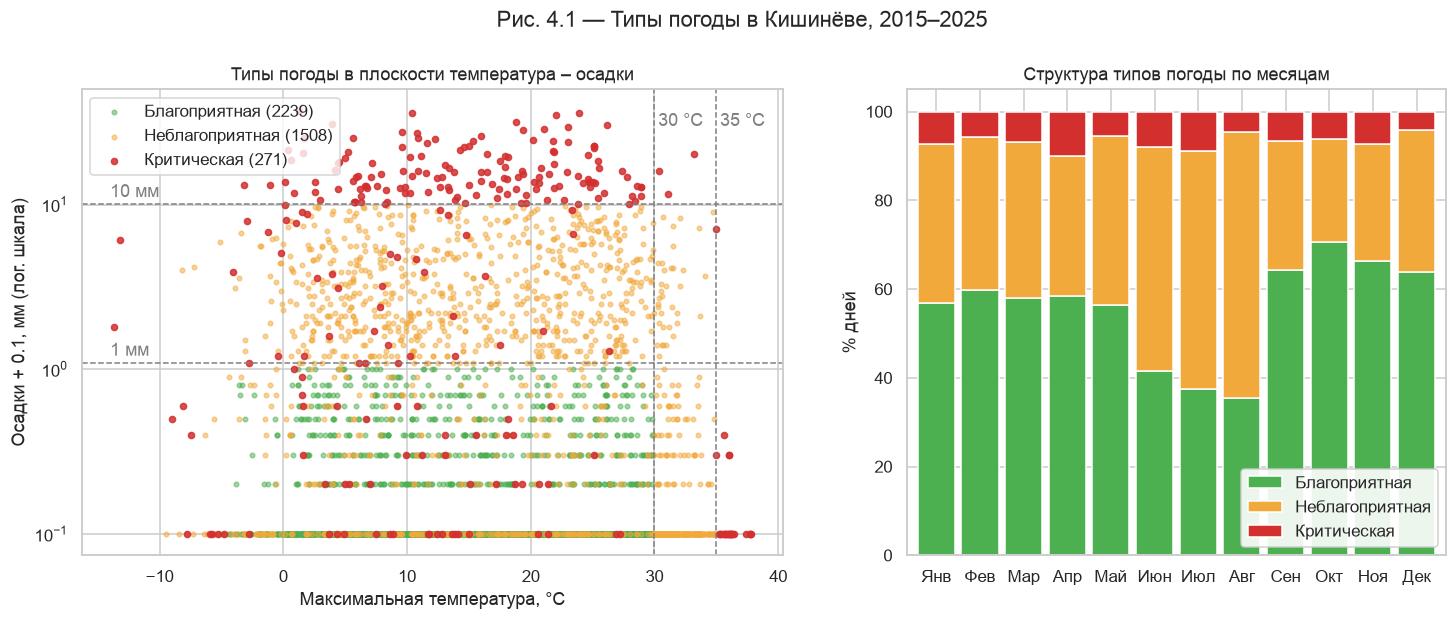

In [3]:
MONTHS = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
for k in (0, 1, 2):
    d = raw_t[raw_t.kind == k]
    a1.scatter(d.temperature_2m_max, d.precipitation_sum + 0.1, s=9 if k < 2 else 16, alpha=0.5 if k < 2 else 0.85,
               color=C3[k], label=f"{WEATHER_TYPES[k]} ({len(d)})")
a1.set_yscale("log")
for y, lab in [(RAIN_MM + 0.1, "1 мм"), (CRITICAL["precip_mm"] + 0.1, "10 мм")]:
    a1.axhline(y, ls="--", color="gray", lw=1); a1.text(-14, y * 1.1, lab, color="gray")
for x, lab in [(UNFAVORABLE["tmax_c"], "30 °C"), (CRITICAL["tmax_c"], "35 °C")]:
    a1.axvline(x, ls="--", color="gray", lw=1); a1.text(x + 0.3, 30, lab, color="gray")
a1.set(xlabel="Максимальная температура, °C", ylabel="Осадки + 0.1, мм (лог. шкала)",
       title="Типы погоды в плоскости температура – осадки")
a1.legend(loc="upper left")
share = pd.crosstab(raw_t.date.dt.month, raw_t.kind, normalize="index") * 100
share.index = MONTHS
share.plot(kind="bar", stacked=True, color=C3, ax=a2, width=0.85, legend=False)
a2.set(ylabel="% дней", xlabel="", title="Структура типов погоды по месяцам"); a2.tick_params(axis="x", rotation=0)
a2.legend(WEATHER_TYPES, loc="lower right", framealpha=0.9)
fig.suptitle("Рис. 4.1 — Типы погоды в Кишинёве, 2015–2025", y=1.01)
save("fig_4_1_weather_types")

**Интерпретация.**
- Распределение: **55.7 % благоприятная, 37.5 % неблагоприятная, 6.7 % критическая** (271 день за 11 лет). Критический класс редок — именно ситуация, описанная в карточке темы для SMOTE.
- Причины критических дней: прежде всего **сильные осадки** (149 дней) и **сильный ветер** (93), гораздо реже жара (25), сильный снегопад (19) и мороз (12). Красные точки у нижней оси на левом графике — критические дни *без* дождя: из-за ветра, жары или мороза.
- Значит, критический класс **неоднороден**: летняя гроза, день жары и день мороза не похожи друг на друга. Это усложнит его классификацию.
- По месяцам: летом (июнь–август) преобладает неблагоприятная погода (жара ≥ 30 °C и ливни), осень (сентябрь–ноябрь) самая благоприятная, а в апреле наибольшая доля критических дней (≈ 10 %).

## A.2 Классификатор типа погоды на завтра (все 26 признаков)

Используем те же параметры Random Forest, что и в базовой модели; сравниваем с мультиномиальной логистической регрессией.

,Balanced acc.,Macro-F1,"ROC-AUC (OvR, macro)",Recall: Благоприятная,Recall: Неблагоприятная,Recall: Критическая,Precision: Критическая
Логистическая регрессия,0.447,0.441,0.727,0.832,0.474,0.035,0.5
Random Forest,0.450,0.432,0.776,0.872,0.478,0.000,0.0


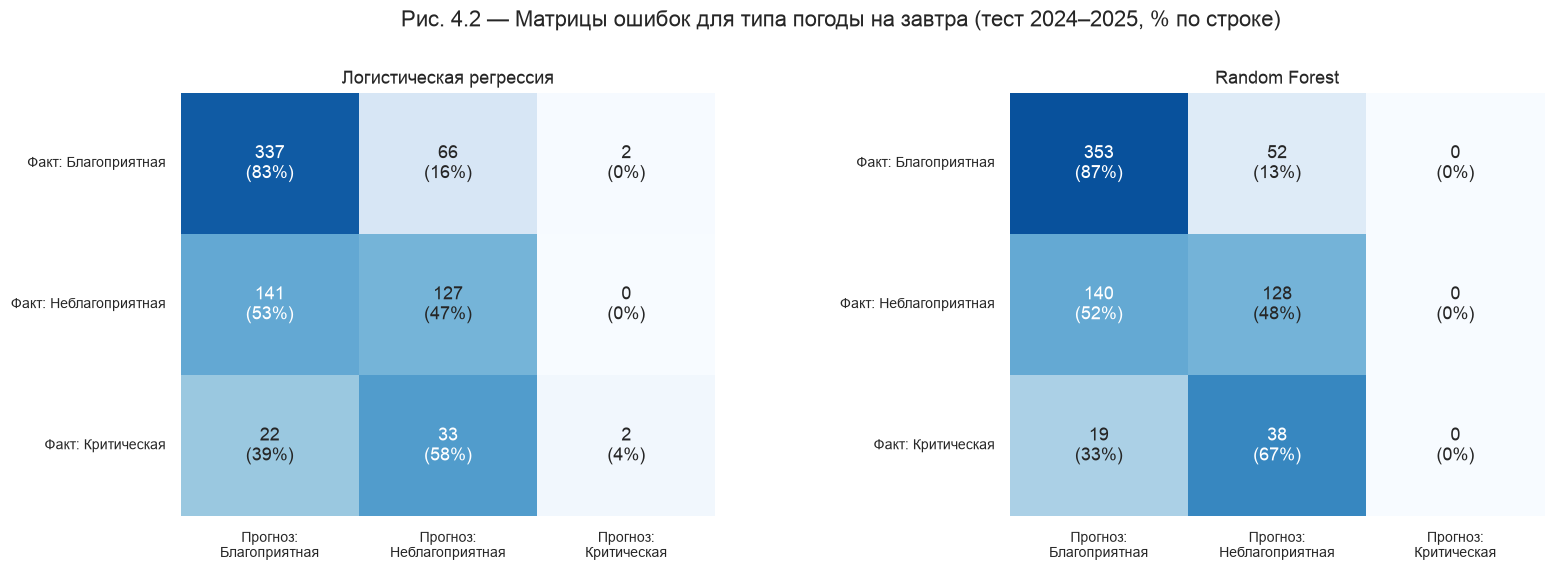

In [4]:
rf3 = clone(rf_base).fit(X_tr, z_tr)
lr3 = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)).fit(X_tr, z_tr)

rows = {}
for name, m in {LR: lr3, RF: rf3}.items():
    pred, proba = m.predict(X_te), m.predict_proba(X_te)
    rows[name] = {"Balanced acc.": balanced_accuracy_score(z_te, pred), "Macro-F1": f1_score(z_te, pred, average="macro"),
                  "ROC-AUC (OvR, macro)": roc_auc_score(z_te, proba, multi_class="ovr"),
                  **{f"Recall: {WEATHER_TYPES[k]}": recall_score(z_te, pred, labels=[k], average=None)[0] for k in (0, 1, 2)},
                  "Precision: Критическая": precision_score(z_te, pred, labels=[2], average=None, zero_division=0)[0]}
res3 = pd.DataFrame(rows).T
display(res3.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, m) in zip(axes, {LR: lr3, RF: rf3}.items()):
    cm = confusion_matrix(z_te, m.predict(X_te))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]}\n({cmn[i, j]:.0%})" for j in range(3)] for i in range(3)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax, vmin=0, vmax=1,
                xticklabels=[f"Прогноз:\n{w}" for w in WEATHER_TYPES], yticklabels=[f"Факт: {w}" for w in WEATHER_TYPES])
    ax.set_title(name); ax.tick_params(axis="x", labelsize=9); ax.tick_params(axis="y", labelsize=9)
plt.subplots_adjust(wspace=0.55)
fig.suptitle("Рис. 4.2 — Матрицы ошибок для типа погоды на завтра (тест 2024–2025, % по строке)", y=1.03)
save("fig_4_2_confusion_3class")

**Интерпретация.** Без какой-либо балансировки Random Forest **ни разу не предсказывает «критическую»** (Recall = 0), а логистическая регрессия — лишь 4 раза: модель «узнаёт», что безопаснее игнорировать редкий класс. Частые классы распознаются (благоприятная — 87 %, неблагоприятная — 48 %), способность ранжировать есть (ROC-AUC OvR ≈ 0.78), но итоговое решение жертвует редкими событиями — именно самыми важными для предупреждений. Это главный аргумент в пользу **SMOTE** (раздел B).

## A.3 Границы решений в пространстве главных компонент (PCA)

26 признаков нельзя нарисовать напрямую. **PCA** (метод главных компонент) проецирует стандартизованные данные на 2 оси, сохраняющие как можно больше их вариации.
Затем обучаем три классификатора **только на этих 2 компонентах** и раскрашиваем плоскость по предсказанному классу — так видна форма границы решений:
- **логистическая регрессия** → **линейные** границы (прямые);
- **SVM с RBF-ядром** → **гладкие, изогнутые** границы;
- **Random Forest** → **ступенчатые** границы (деревья режут пространство параллельно осям).

In [5]:
scaler = StandardScaler().fit(X_tr)
pca = PCA(n_components=2, random_state=SEED).fit(scaler.transform(X_tr))
P_tr, P_te = pca.transform(scaler.transform(X_tr)), pca.transform(scaler.transform(X_te))
ev = pca.explained_variance_ratio_
print(f"Объяснённая дисперсия: PC1 = {ev[0]:.1%}, PC2 = {ev[1]:.1%}, всего = {ev.sum():.1%}")

load = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"])
print("\nНаибольшие нагрузки (loadings):")
for pc in ("PC1", "PC2"):
    top = load[pc].abs().sort_values(ascending=False).head(5).index
    print(f"  {pc}: " + ", ".join(f"{f} ({load.loc[f, pc]:+.2f})" for f in top))

Объяснённая дисперсия: PC1 = 29.8%, PC2 = 13.5%, всего = 43.3%

Наибольшие нагрузки (loadings):
  PC1: vapour_pressure_deficit_max (+0.32), dew_point_depression (+0.32), relative_humidity_2m_mean (-0.30), soil_moisture_0_to_7cm_mean (-0.28), sunshine_ratio (+0.27)
  PC2: dew_point_2m_mean (+0.39), pressure_msl_mean (-0.36), precipitation_sum (+0.35), precipitation_hours (+0.32), temperature_2m_mean (+0.31)


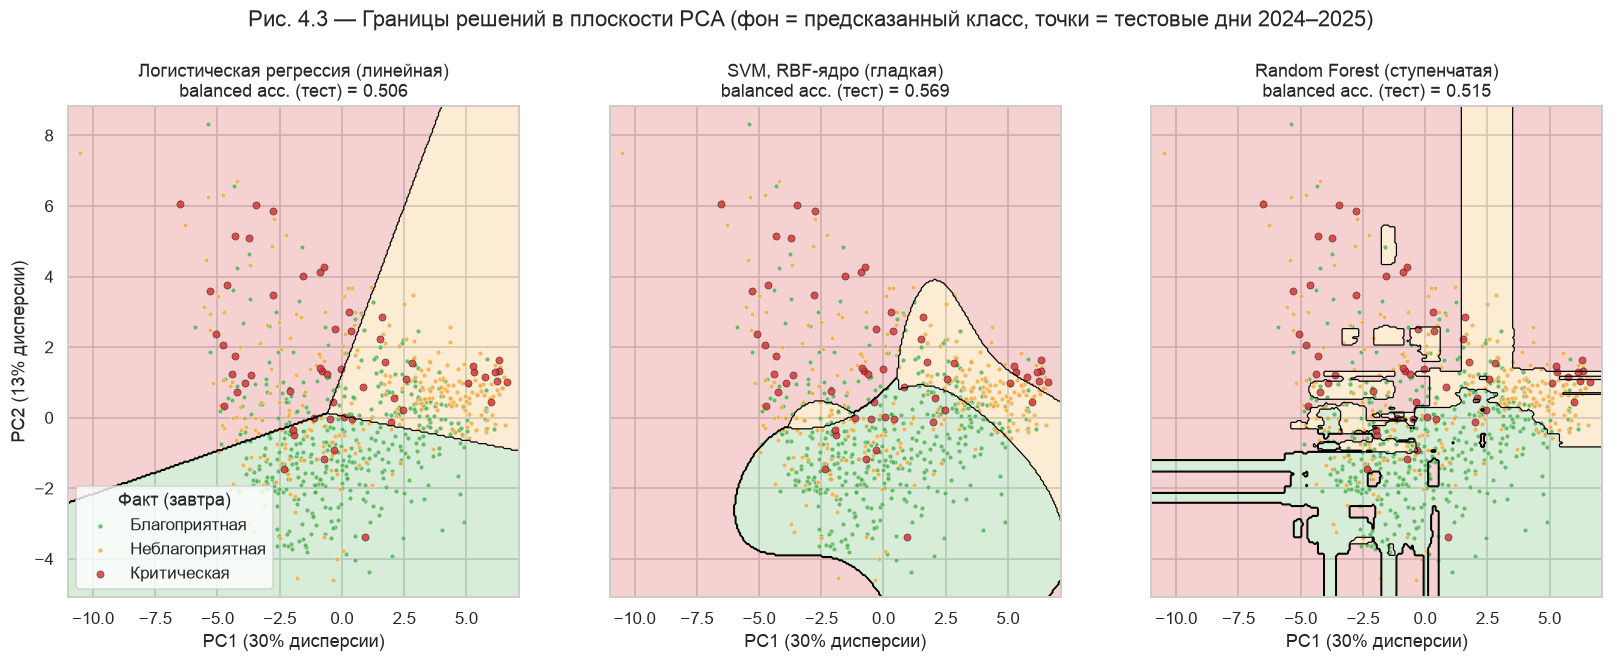

In [6]:
clfs2d = {
    "Логистическая регрессия (линейная)": LogisticRegression(C=1, max_iter=5000, class_weight="balanced"),
    "SVM, RBF-ядро (гладкая)": SVC(C=1, gamma="scale", class_weight="balanced", random_state=SEED),
    "Random Forest (ступенчатая)": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced",
                                                          random_state=SEED, n_jobs=-1),
}
xx, yy = np.meshgrid(np.linspace(P_te[:, 0].min() - 0.5, P_te[:, 0].max() + 0.5, 300),
                     np.linspace(P_te[:, 1].min() - 0.5, P_te[:, 1].max() + 0.5, 300))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), sharey=True)
bacc2d = {}
for ax, (name, clf) in zip(axes, clfs2d.items()):
    clf.fit(P_tr, z_tr)
    bacc2d[name] = balanced_accuracy_score(z_te, clf.predict(P_te))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=C3, alpha=0.22)
    ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors="black", linewidths=0.8)
    for k in (0, 1, 2):
        m = z_te.values == k
        ax.scatter(P_te[m, 0], P_te[m, 1], s=10 if k < 2 else 22, color=C3[k], edgecolor="white" if k < 2 else "black",
                   linewidth=0.3, alpha=0.8, label=WEATHER_TYPES[k])
    ax.set(xlim=(xx.min(), xx.max()), ylim=(yy.min(), yy.max()), xlabel=f"PC1 ({ev[0]:.0%} дисперсии)",
           title=f"{name}\nbalanced acc. (тест) = {bacc2d[name]:.3f}")
axes[0].set_ylabel(f"PC2 ({ev[1]:.0%} дисперсии)"); axes[0].legend(title="Факт (завтра)", loc="lower left")
fig.suptitle("Рис. 4.3 — Границы решений в плоскости PCA (фон = предсказанный класс, точки = тестовые дни 2024–2025)", y=1.03)
save("fig_4_3_pca_boundaries")

**Интерпретация.**
- Первые 2 компоненты сохраняют **43 %** вариации 26 признаков. **PC1** — ось **«сухо ↔ влажно»** (дефицит упругости пара и дефицит точки росы со знаком +, влажность воздуха и почвы со знаком −), **PC2** — ось **«тепло, влажно, низкое давление, дождь»** (точка росы, осадки, температура с +, давление с −).
- Форма границ иллюстрирует разницу алгоритмов: **прямая** у логистической регрессии, **гладкая кривая** у SVM, **ступенчатая с «островками»** у Random Forest (маленькие островки — признак переобучения на шум).
- Критические дни образуют **две отдельные группы**: слева вверху (влажный воздух, низкое давление → грозы и сильные осадки) и справа (очень сухой и тёплый воздух → жара). Это подтверждает неоднородность критического класса и объясняет, почему линейная модель не может хорошо его отделить.
- В центре плоскости классы сильно перекрываются: **чёткой границы нет** между благоприятной и неблагоприятной погодой — завтрашняя погода не полностью определяется сегодняшней.
- Всего на 2 компонентах (все модели с `class_weight="balanced"`) SVM достигает balanced accuracy ≈ 0.57 — сравнимо со сбалансированным Random Forest на всех 26 признаках (≈ 0.57, раздел B).

## A.4 Границы решений в плоскости температура – давление («температурные графики»)

PCA абстрактен. Для наглядной картины обучаем модель только на **сегодняшней средней температуре** и **сегодняшнем давлении** — двух величинах, понятных каждому.

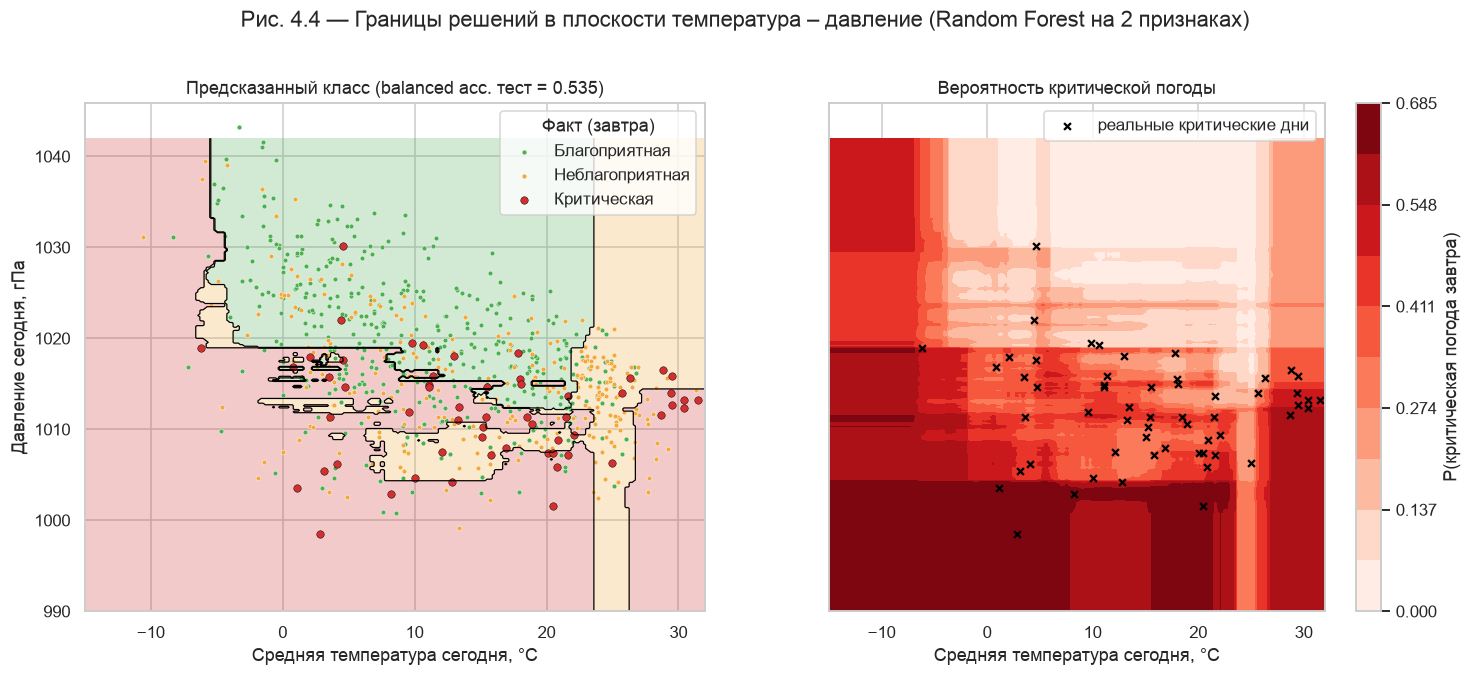

In [7]:
f2 = ["temperature_2m_mean", "pressure_msl_mean"]
rf2 = RandomForestClassifier(n_estimators=300, min_samples_leaf=30, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf2.fit(train[f2], z_tr)
xx2, yy2 = np.meshgrid(np.linspace(-15, 32, 300), np.linspace(990, 1042, 300))
grid2 = pd.DataFrame(np.c_[xx2.ravel(), yy2.ravel()], columns=f2)
Z2 = rf2.predict(grid2).reshape(xx2.shape)
P2 = rf2.predict_proba(grid2)[:, 2].reshape(xx2.shape)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
a1.contourf(xx2, yy2, Z2, levels=[-0.5, 0.5, 1.5, 2.5], colors=C3, alpha=0.25)
a1.contour(xx2, yy2, Z2, levels=[0.5, 1.5], colors="black", linewidths=0.8)
for k in (0, 1, 2):
    m = z_te.values == k
    a1.scatter(test.loc[m, f2[0]], test.loc[m, f2[1]], s=10 if k < 2 else 24, color=C3[k],
               edgecolor="white" if k < 2 else "black", linewidth=0.3, label=WEATHER_TYPES[k])
a1.set(xlabel="Средняя температура сегодня, °C", ylabel="Давление сегодня, гПа",
       title=f"Предсказанный класс (balanced acc. тест = {balanced_accuracy_score(z_te, rf2.predict(test[f2])):.3f})")
a1.legend(title="Факт (завтра)", loc="upper right")
cs = a2.contourf(xx2, yy2, P2, levels=np.linspace(0, P2.max(), 11), cmap="Reds")
plt.colorbar(cs, ax=a2, label="P(критическая погода завтра)")
crit = z_te.values == 2
a2.scatter(test.loc[crit, f2[0]], test.loc[crit, f2[1]], s=20, color="black", marker="x", label="реальные критические дни")
a2.set(xlabel="Средняя температура сегодня, °C", title="Вероятность критической погоды"); a2.legend(loc="upper right")
fig.suptitle("Рис. 4.4 — Границы решений в плоскости температура – давление (Random Forest на 2 признаках)", y=1.02)
save("fig_4_4_temp_pressure_boundaries")

**Интерпретация.** Плоскость температура – давление показывает правила, которые выучила модель:
- **высокое давление (> 1020 гПа)** → благоприятная погода (антициклон, ясное небо);
- **низкое давление (< 1010 гПа)** → риск критической погоды (циклоны, фронты, грозы);
- **высокая температура (> 24 °C)** → неблагоприятная погода, а выше ≈ 28 °C — риск критической (жара на следующий день).

Карта вероятностей (справа) показывает, что критический риск максимален при **низком давлении** и при **экстремальных температурах** — «что говорит небо, прежде чем заговорить». Зубчатые границы и мелкие островки — эффект переобучения Random Forest на отдельные дни.

## A.5 Карта t-SNE

**t-SNE** — нелинейный метод снижения размерности: он сохраняет **соседство** (похожие дни остаются рядом), но большие расстояния и оси не имеют физического смысла. Используем его только для визуализации.

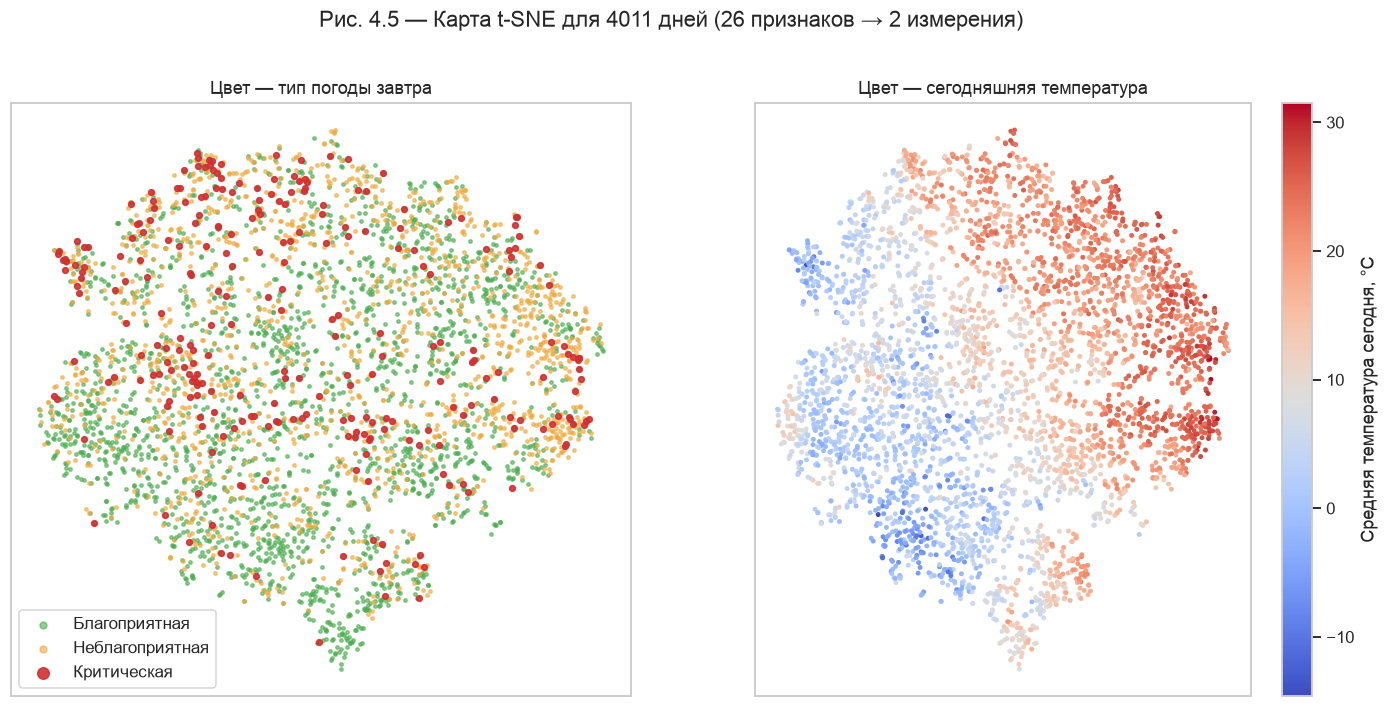

In [8]:
X_all = scaler.transform(data[FEATURES])
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(X_all)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for k in (0, 1, 2):
    m = data[TARGET3].values == k
    axes[0].scatter(emb[m, 0], emb[m, 1], s=5 if k < 2 else 14, color=C3[k], alpha=0.6 if k < 2 else 0.9,
                    label=WEATHER_TYPES[k], zorder=k)
axes[0].set_title("Цвет — тип погоды завтра"); axes[0].legend(markerscale=2)
sc = axes[1].scatter(emb[:, 0], emb[:, 1], s=5, c=data.temperature_2m_mean, cmap="coolwarm")
plt.colorbar(sc, ax=axes[1], label="Средняя температура сегодня, °C")
axes[1].set_title("Цвет — сегодняшняя температура")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Рис. 4.5 — Карта t-SNE для 4011 дней (26 признаков → 2 измерения)", y=1.0)
save("fig_4_5_tsne")

**Интерпретация.** Карта t-SNE организована прежде всего по **температуре / сезону** (цветовой градиент справа): дни одного сезона лежат рядом. Критические дни **не образуют отдельной группы**, а разбросаны по краям разных областей (летние грозы, зимний мороз, жара). Вывод: в пространстве сегодняшних признаков у критической погоды завтра нет единой «подписи» — поэтому её обнаружение остаётся трудной задачей.

---
# B. SMOTE — балансировка редких классов

## B.1 Как работает SMOTE

**SMOTE** (*Synthetic Minority Over-sampling Technique*) создаёт **синтетические** примеры редкого класса: берёт редкий пример $x_i$, одного из его *k* редких соседей $x_{nn}$ и создаёт новую точку на отрезке между ними:

$$x_{new} = x_i + \lambda \cdot (x_{nn} - x_i), \quad \lambda \sim U(0, 1)$$

Правила корректного применения:
- SMOTE применяется **только к обучающей выборке** (внутри пайплайна), никогда к валидации/тесту — иначе оценка будет фальсифицирована;
- данные **стандартизуются до** SMOTE, так как соседи ищутся по расстоянию.

Редкий класс в нашей задаче — **критическая погода** (≈ 7 % дней; в обучающей выборке — см. ниже).

Распределение классов в обучающей выборке:
weather_type_tomorrow
Благоприятная      1638
Неблагоприятная    1088
Критическая         190

После SMOTE: {'Благоприятная': 1638, 'Неблагоприятная': 1638, 'Критическая': 1638}  (+1998 синтетических примеров)


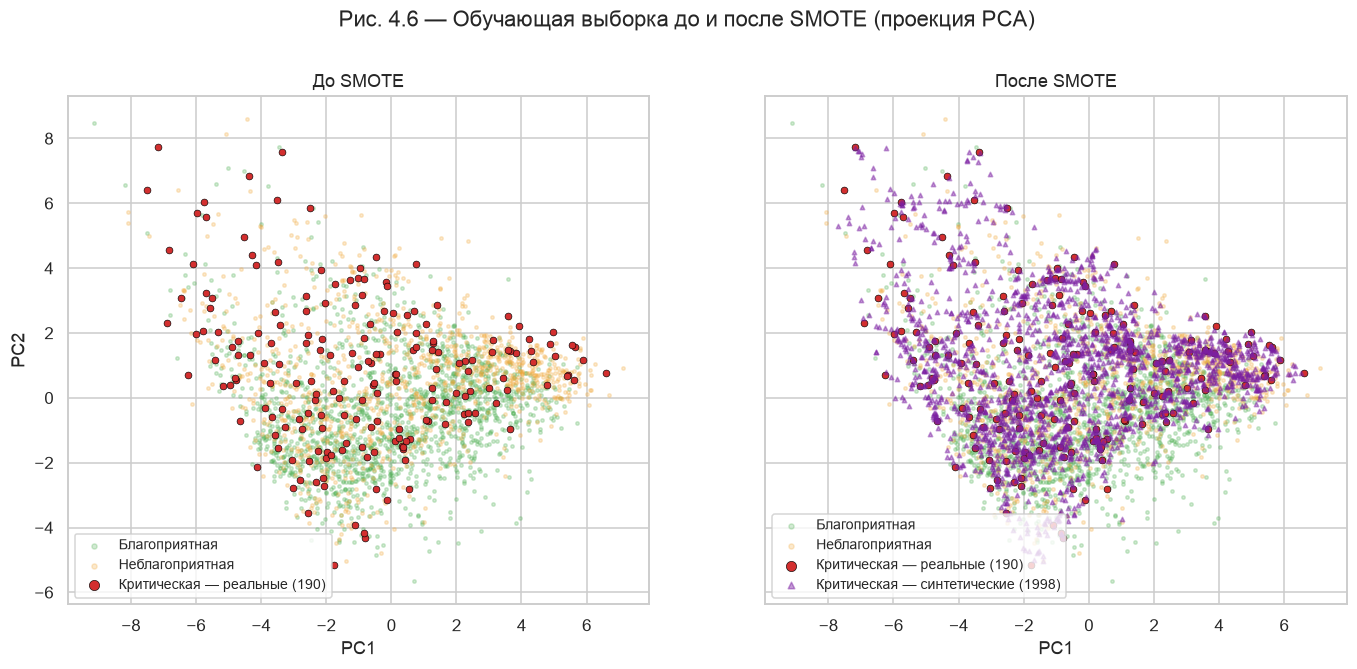

In [9]:
print("Распределение классов в обучающей выборке:")
print(z_tr.value_counts().sort_index().rename(dict(enumerate(WEATHER_TYPES))).to_string())

sc_tr = StandardScaler().fit(X_tr)
Xs = sc_tr.transform(X_tr)
Xr, zr = SMOTE(random_state=SEED).fit_resample(Xs, z_tr)
synthetic = np.arange(len(Xr)) >= len(Xs)
print(f"\nПосле SMOTE: {pd.Series(zr).value_counts().sort_index().rename(dict(enumerate(WEATHER_TYPES))).to_dict()}"
      f"  (+{synthetic.sum()} синтетических примеров)")

pca_s = PCA(2, random_state=SEED).fit(Xs)
A, B = pca_s.transform(Xs), pca_s.transform(Xr[synthetic])
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, title in zip(axes, ["До SMOTE", "После SMOTE"]):
    for k in (0, 1):
        m = z_tr.values == k
        ax.scatter(A[m, 0], A[m, 1], s=5, color=C3[k], alpha=0.25, label=WEATHER_TYPES[k])
    m = z_tr.values == 2
    ax.scatter(A[m, 0], A[m, 1], s=20, color=C3[2], edgecolor="black", linewidth=0.4, label=f"Критическая — реальные ({m.sum()})")
    ax.set_title(title); ax.set_xlabel("PC1")
axes[1].scatter(B[:, 0], B[:, 1], s=8, color="#7B1FA2", alpha=0.45, marker="^", label=f"Критическая — синтетические ({len(B)})")
axes[0].set_ylabel("PC2")
for ax in axes: ax.legend(loc="lower left", markerscale=1.5, fontsize=9)
fig.suptitle("Рис. 4.6 — Обучающая выборка до и после SMOTE (проекция PCA)", y=1.01)
save("fig_4_6_smote_pca")

## B.2 Сравнение стратегий балансировки (классификация типа погоды, 3 класса)

| Стратегия | Что делает |
|---|---|
| Без балансировки | данные как есть |
| `class_weight="balanced"` | не меняет данные, но сильнее штрафует ошибки на редких классах |
| Random Over-Sampling | случайно копирует редкие примеры |
| Random Under-Sampling | случайно удаляет примеры частых классов |
| **SMOTE** | создаёт синтетические редкие примеры интерполяцией |
| Borderline-SMOTE | SMOTE только для редких примеров на **границе** между классами |

In [10]:
def strategy_pipe(strategy, model):
    m = clone(model)
    steps = [("scale", StandardScaler())]
    if strategy == "class_weight": m.set_params(class_weight="balanced")
    elif strategy == "ROS": steps.append(("sampler", RandomOverSampler(random_state=SEED)))
    elif strategy == "RUS": steps.append(("sampler", RandomUnderSampler(random_state=SEED)))
    elif strategy == "SMOTE": steps.append(("sampler", SMOTE(random_state=SEED)))
    elif strategy == "Borderline-SMOTE": steps.append(("sampler", BorderlineSMOTE(random_state=SEED)))
    return ImbPipeline(steps + [("model", m)])

STRATS = {"none": "Без балансировки", "class_weight": "class_weight", "ROS": "Random Over-Sampling",
          "RUS": "Random Under-Sampling", "SMOTE": "SMOTE", "Borderline-SMOTE": "Borderline-SMOTE"}
base_models = {RF: clone(rf_base), LR: LogisticRegression(C=0.1, max_iter=5000)}

rows = []
for mname, model in base_models.items():
    for s, sname in STRATS.items():
        pipe = strategy_pipe(s, model).fit(X_tr, z_tr)
        pred = pipe.predict(X_te)
        rows.append({"Модель": mname, "Стратегия": sname,
                     "Recall (крит.)": recall_score(z_te, pred, labels=[2], average=None)[0],
                     "Precision (крит.)": precision_score(z_te, pred, labels=[2], average=None, zero_division=0)[0],
                     "F1 (крит.)": f1_score(z_te, pred, labels=[2], average=None)[0],
                     "Macro-F1": f1_score(z_te, pred, average="macro"),
                     "Balanced acc.": balanced_accuracy_score(z_te, pred),
                     "Дней предсказано как крит.": int((pred == 2).sum())})
smote_tbl = pd.DataFrame(rows).set_index(["Модель", "Стратегия"])
print(f"Реальных критических дней в тесте: {(z_te == 2).sum()} из {len(z_te)}")
smote_tbl.round(3)

Реальных критических дней в тесте: 57 из 730


Recall (крит.)  \
Модель                  Стратегия                               
Random Forest           Без балансировки                0.000   
                        class_weight                    0.509   
                        Random Over-Sampling            0.316   
                        Random Under-Sampling           0.632   
                        SMOTE                           0.298   
                        Borderline-SMOTE                0.316   
Логистическая регрессия Без балансировки                0.035   
                        class_weight                    0.509   
                        Random Over-Sampling            0.456   
                        Random Under-Sampling           0.404   
                        SMOTE                           0.491   
                        Borderline-SMOTE                0.509   

                                               Precision (крит.)  F1 (крит.)  \
Модель                  Стратегия                                              
Random Forest           Без балансировки                   0.000       0.000   
                        class_weight                       0.234       0.320   
                        Random Over-Sampling               0.212       0.254   
                        Random Under-Sampling              0.174       0.273   
                        SMOTE                              0.200       0.239   
                        Borderline-SMOTE                   0.222       0.261   
Логистическая регрессия Без балансировки                   0.500       0.066   
                        class_weight                       0.197       0.284   
                        Random Over-Sampling               0.176       0.254   
                        Random Under-Sampling              0.138       0.205   
                        SMOTE                              0.189       0.273   
                        Borderline-SMOTE                   0.195       0.282   

                                               Macro-F1  Balanced acc.  \
Модель                  Стратегия                                        
Random Forest           Без балансировки          0.431          0.448   
                        class_weight              0.526          0.568   
                        Random Over-Sampling      0.507          0.518   
                        Random Under-Sampling     0.484          0.561   
                        SMOTE                     0.508          0.519   
                        Borderline-SMOTE          0.518          0.528   
Логистическая регрессия Без балансировки          0.441          0.447   
                        class_weight              0.484          0.533   
                        Random Over-Sampling      0.473          0.514   
                        Random Under-Sampling     0.432          0.469   
                        SMOTE                     0.479          0.525   
                        Borderline-SMOTE          0.471          0.521   

                                               Дней предсказано как крит.  
Модель                  Стратегия                                          
Random Forest           Без балансировки                                0  
                        class_weight                                  124  
                        Random Over-Sampling                           85  
                        Random Under-Sampling                         207  
                        SMOTE                                          85  
                        Borderline-SMOTE                               81  
Логистическая регрессия Без балансировки                                4  
                        class_weight                                  147  
                        Random Over-Sampling                          148  
                        Random Under-Sampling                         167  
                        SMOTE                                     

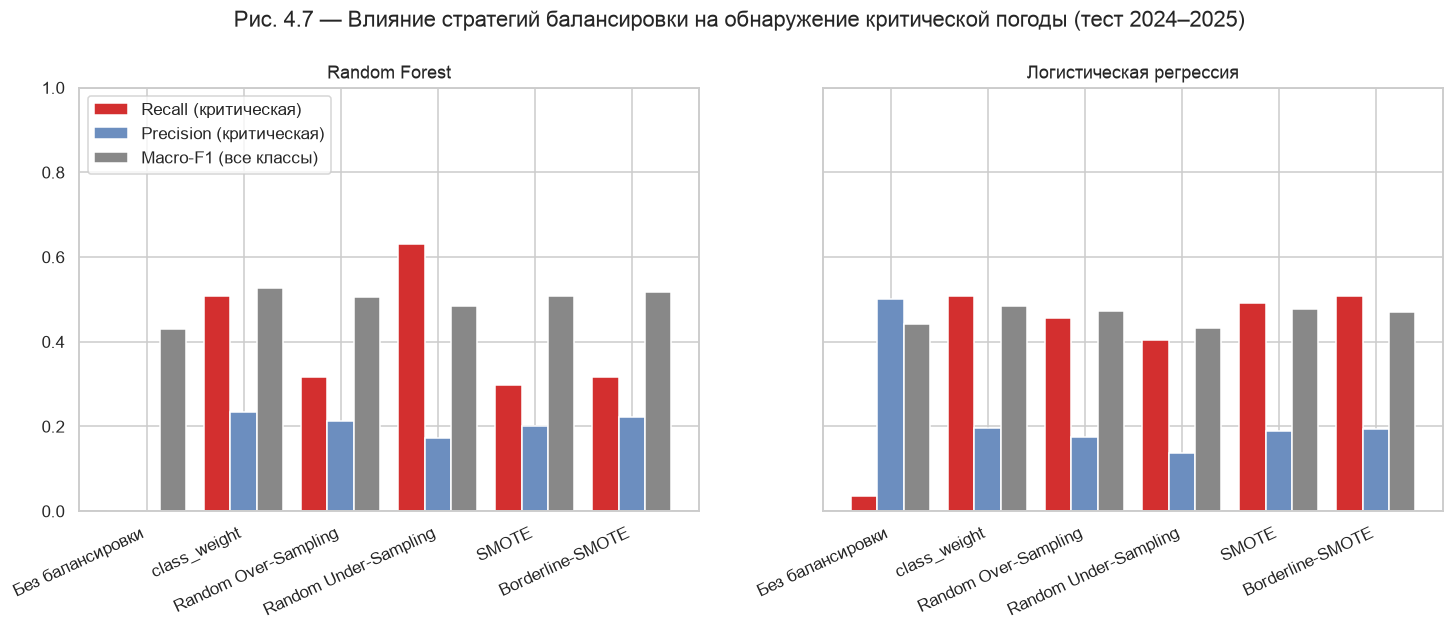

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, mname in zip(axes, base_models):
    t = smote_tbl.loc[mname]
    x = np.arange(len(t)); w = 0.27
    ax.bar(x - w, t["Recall (крит.)"], w, label="Recall (критическая)", color="#D32F2F")
    ax.bar(x, t["Precision (крит.)"], w, label="Precision (критическая)", color="#6C8EBF")
    ax.bar(x + w, t["Macro-F1"], w, label="Macro-F1 (все классы)", color="#888888")
    ax.set_xticks(x, t.index, rotation=25, ha="right"); ax.set_title(mname); ax.set_ylim(0, 1)
axes[0].legend(loc="upper left")
fig.suptitle("Рис. 4.7 — Влияние стратегий балансировки на обнаружение критической погоды (тест 2024–2025)", y=1.02)
save("fig_4_7_smote_strategies")

**Интерпретация.**
- В тестовой выборке **57 критических дней** из 730. Без балансировки Random Forest не находит ни одного.
- **Все стратегии повышают чувствительность** к критическому классу — ровно эффект, обещанный в карточке темы: SMOTE поднимает Recall с 0 до 0.30 (Random Forest) и с 0.04 до 0.49 (логистическая регрессия).
- Однако для Random Forest лучшей стратегией оказался **`class_weight`** (Recall 0.51, F1 0.32, лучший Macro-F1 0.53), а не SMOTE. У Random Under-Sampling максимальный Recall (0.63), но он предсказывает 207 критических дней — слишком много ложных тревог.
- Для логистической регрессии SMOTE, Borderline-SMOTE и `class_weight` дают близкие результаты (Recall ≈ 0.49–0.51).
- **Почему SMOTE не выиграл у Random Forest?** Критический класс неоднороден (грозы + жара + мороз, см. A.3). SMOTE интерполирует между соседями, которые могут быть совсем разными днями, и создаёт «погоду», которой не бывает в природе (рис. 4.6: синтетические точки заполняют области между группами). Кроме того, по умолчанию SMOTE генерирует примеры и для класса «неблагоприятная» (см. B.3).
- **Precision ≈ 0.2** для критического класса: из 5 критических тревог подтверждается одна. Для системы предупреждений такой компромисс приемлем — цена пропущенной бури намного выше цены ложной тревоги.

## B.3 Насколько сильно балансировать? (параметр `sampling_strategy`)

SMOTE не обязан уравнивать классы. Меняем количество синтетических критических примеров (как долю от мажоритарного класса) и следим за компромиссом Recall / Precision для критического класса.

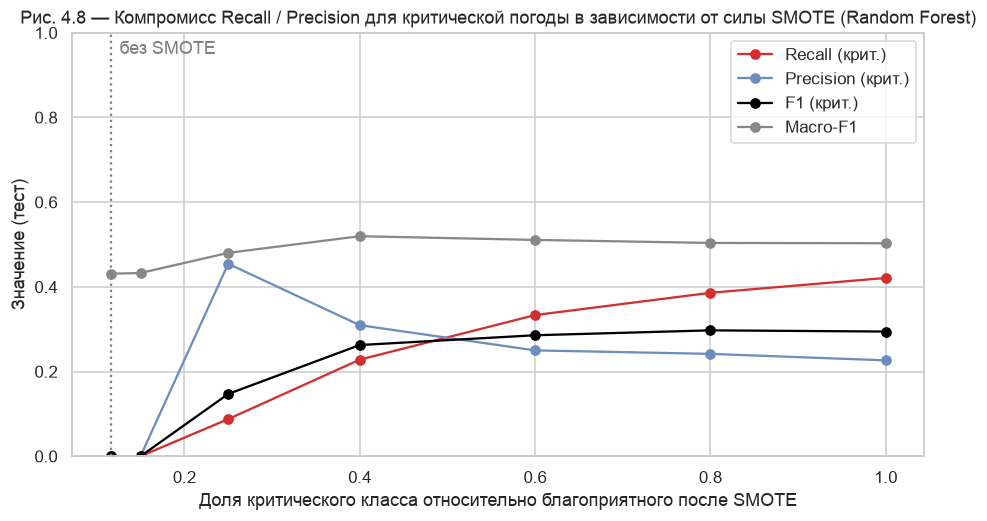

,Доля крит. / благопр.,Recall (крит.),Precision (крит.),F1 (крит.),Macro-F1
0,0.116,0.000,0.000,0.000,0.431
1,0.150,0.000,0.000,0.000,0.433
2,0.250,0.088,0.455,0.147,0.480
3,0.400,0.228,0.310,0.263,0.520
4,0.600,0.333,0.250,0.286,0.511
5,0.800,0.386,0.242,0.297,0.504
6,1.000,0.421,0.226,0.294,0.503


In [12]:
n_major = (z_tr == 0).sum()
ratios = [None, 0.15, 0.25, 0.4, 0.6, 0.8, 1.0]
sweep = []
for r in ratios:
    if r is None:
        pipe = ImbPipeline([("scale", StandardScaler()), ("model", clone(rf_base))])
    else:
        target_n = max(int(r * n_major), (z_tr == 2).sum())
        pipe = ImbPipeline([("scale", StandardScaler()),
                            ("sampler", SMOTE(sampling_strategy={2: target_n}, random_state=SEED)),
                            ("model", clone(rf_base))])
    pred = pipe.fit(X_tr, z_tr).predict(X_te)
    sweep.append({"Доля крит. / благопр.": (z_tr == 2).sum() / n_major if r is None else r,
                  "Recall (крит.)": recall_score(z_te, pred, labels=[2], average=None)[0],
                  "Precision (крит.)": precision_score(z_te, pred, labels=[2], average=None, zero_division=0)[0],
                  "F1 (крит.)": f1_score(z_te, pred, labels=[2], average=None)[0],
                  "Macro-F1": f1_score(z_te, pred, average="macro")})
sweep = pd.DataFrame(sweep)
fig, ax = plt.subplots(figsize=(10, 5))
for c, col in zip(["Recall (крит.)", "Precision (крит.)", "F1 (крит.)", "Macro-F1"], ["#D32F2F", "#6C8EBF", "black", "#888888"]):
    ax.plot(sweep["Доля крит. / благопр."], sweep[c], "o-", color=col, label=c)
ax.axvline(sweep.iloc[0, 0], ls=":", color="gray"); ax.text(sweep.iloc[0, 0] + 0.01, 0.95, "без SMOTE", color="gray")
ax.set(xlabel="Доля критического класса относительно благоприятного после SMOTE", ylabel="Значение (тест)", ylim=(0, 1),
       title="Рис. 4.8 — Компромисс Recall / Precision для критической погоды в зависимости от силы SMOTE (Random Forest)")
ax.legend()
save("fig_4_8_smote_ratio")
sweep.round(3)

**Интерпретация.**
- Слабая балансировка (доля ≤ 0.15) ничего не меняет: модель по-прежнему не предсказывает «критическую».
- Чем больше синтетических примеров, тем **выше Recall** (0.09 → 0.42) и **ниже Precision** (0.45 → 0.23) — типичный компромисс.
- Macro-F1 максимален при доле ≈ 0.4 (0.52), F1 для критического класса — при ≈ 0.6–0.8 (≈ 0.29–0.30).
- Применённый только к критическому классу с долей 1.0, SMOTE достигает Recall 0.42 — больше, чем SMOTE по умолчанию из B.2 (0.30), который «раздувал» и класс «неблагоприятная».
- **Выбор силы SMOTE — бизнес-решение:** экстренной службе нужен высокий Recall, организатору мероприятий — меньше ложных тревог.

## B.4 SMOTE vs. выбор порога (бинарная задача «дождь завтра»)

В ноутбуке 02 дисбаланс компенсировался **выбором порога** решения. Сравним два подхода на бинарной задаче.

In [13]:
bin_rows = {}
for name, pipe in {"Без балансировки": ImbPipeline([("scale", StandardScaler()), ("model", clone(rf_base))]),
                   "SMOTE": ImbPipeline([("scale", StandardScaler()), ("sampler", SMOTE(random_state=SEED)), ("model", clone(rf_base))]),
                   "class_weight": ImbPipeline([("scale", StandardScaler()), ("model", clone(rf_base).set_params(class_weight="balanced"))])}.items():
    pipe.fit(X_tr, y_tr)
    pv, pt = pipe.predict_proba(X_va)[:, 1], pipe.predict_proba(X_te)[:, 1]
    t = tune_threshold(y_va, pv)
    bin_rows[name] = {"ROC-AUC": roc_auc_score(y_te, pt), "PR-AUC": average_precision_score(y_te, pt),
                      "Средняя предск. вероятность": pt.mean(), "Реальная частота": y_te.mean(),
                      "F1 @0.5": f1_score(y_te, pt >= 0.5), "Recall @0.5": recall_score(y_te, pt >= 0.5),
                      "Оптим. порог (валид.)": t, "F1 @опт. порог": f1_score(y_te, pt >= t), "Recall @опт. порог": recall_score(y_te, pt >= t)}
pd.DataFrame(bin_rows).T.round(3)

,ROC-AUC,PR-AUC,Средняя предск. вероятность,Реальная частота,F1 @0.5,Recall @0.5,Оптим. порог (валид.),F1 @опт. порог,Recall @опт. порог
Без балансировки,0.793,0.551,0.237,0.221,0.421,0.298,0.23,0.520,0.758
SMOTE,0.776,0.532,0.365,0.221,0.483,0.540,0.48,0.497,0.584
class_weight,0.798,0.560,0.410,0.221,0.518,0.665,0.38,0.511,0.851


**Интерпретация.**
- В бинарной задаче SMOTE **не улучшает различающую способность** (ROC-AUC 0.776 против 0.793) и **портит калибровку**: средняя предсказанная вероятность вырастает до 0.37, хотя реально дождь идёт в 22 % дней.
- При стандартном пороге 0.5 SMOTE кажется полезным (F1 0.48 против 0.42), но после выбора порога на валидации лучшей оказывается модель без балансировки (F1 0.52 против 0.50).
- **Вывод:** SMOTE по сути — ещё один способ сдвинуть порог решения. Если модель выдаёт вероятности и порог можно выбрать, SMOTE не даёт выигрыша; он полезен, когда решение принимается при фиксированном пороге, или в многоклассовых задачах (раздел B.2), где нет одного порога для настройки.

---
# C. Noise — устойчивость к ошибкам датчиков, пропускам и интерполяции

Данные ERA5 «чистые». У реальной метеостанции есть **шум измерений**, **пропуски** (отключения питания, сбои передачи), **зависшие датчики** и **ошибки записи**.
Моделируем эти проблемы на **сырых** данных тестового периода и пересчитываем признаки той же функцией `compute_features`, как это происходило бы в реальной системе.
Модель (обученная на чистых данных) не меняется — проверяем **устойчивость прогноза**. Оценка всегда проводится по **тому, что произошло на самом деле** (истинные метки), а не по тому, что записали испорченные датчики.

In [14]:
SENSORS = {
    "Температура": ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "apparent_temperature_mean"],
    "Влажность": ["relative_humidity_2m_mean", "relative_humidity_2m_max", "relative_humidity_2m_min",
                  "dew_point_2m_mean", "vapour_pressure_deficit_max"],
    "Давление": ["pressure_msl_mean", "pressure_msl_max", "pressure_msl_min"],
    "Облачность / солнце": ["cloud_cover_mean", "sunshine_duration", "shortwave_radiation_sum"],
    "Осадкомер": ["precipitation_sum", "rain_sum", "snowfall_sum", "precipitation_hours"],
    "Ветер": ["wind_speed_10m_max", "wind_gusts_10m_max", "wind_direction_10m_dominant"],
    "Почва": ["soil_moisture_0_to_7cm_mean"],
}
SENSOR_COLS = [c for cols in SENSORS.values() for c in cols]
raw = raw.astype({c: "float64" for c in SENSOR_COLS})   # some columns are integers in the CSV; the noise is real-valued
raw_std = raw[raw.date.dt.year <= 2022][SENSOR_COLS].std()
# corruption is applied to the test period + 7 days of history (needed for the lags)
NOISY_PERIOD = raw.date >= test.date.min() - pd.Timedelta(days=7)

def clip_physical(df):
    df = df.copy()
    for c in ["relative_humidity_2m_mean", "relative_humidity_2m_max", "relative_humidity_2m_min", "cloud_cover_mean"]:
        df[c] = df[c].clip(0, 100)
    for c in ["precipitation_sum", "rain_sum", "snowfall_sum", "precipitation_hours", "sunshine_duration",
              "shortwave_radiation_sum", "wind_speed_10m_max", "wind_gusts_10m_max", "vapour_pressure_deficit_max",
              "soil_moisture_0_to_7cm_mean"]:
        df[c] = df[c].clip(lower=0)
    df["precipitation_hours"] = df.precipitation_hours.clip(upper=24)
    df["sunshine_duration"] = np.minimum(df.sunshine_duration, df.daylight_duration)
    df["wind_direction_10m_dominant"] = df.wind_direction_10m_dominant % 360
    return df

def evaluate_raw(raw_mod, models):
    # features come from the corrupted data, but the labels (what actually happened) stay the true ones
    t = test[["date", TARGET]].merge(compute_features(raw_mod), on="date")
    assert len(t) == len(test) and not t[FEATURES].isna().any().any()
    out = {}
    for name, (m, thr) in models.items():
        p = m.predict_proba(t[FEATURES])[:, 1]
        out[name] = (roc_auc_score(t[TARGET], p), f1_score(t[TARGET], p >= thr))
    return out

lr_bin = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)).fit(X_tr, y_tr)
lr_thr = tune_threshold(y_va, lr_bin.predict_proba(X_va)[:, 1])
MODELS = {RF: (rf_base, THR), LR: (lr_bin, lr_thr)}
clean = evaluate_raw(raw, MODELS)
print("Без шума:", {k: f"AUC={v[0]:.3f}, F1={v[1]:.3f}" for k, v in clean.items()})

Без шума: {'Random Forest': 'AUC=0.793, F1=0.519', 'Логистическая регрессия': 'AUC=0.773, F1=0.524'}


## C.1 Гауссов шум измерений

К каждой измеряемой величине добавляется $\varepsilon \sim N(0, (k \cdot \sigma)^2)$, где $\sigma$ — стандартное отклонение величины, а $k$ — интенсивность шума (например, при $k=0.1$ для давления это ≈ ±0.8 гПа, для температуры ≈ ±1 °C). Для каждого уровня повторяем 5 раз.

In [15]:
def add_gaussian(raw_in, k, rng):
    r = raw_in.copy()
    idx = NOISY_PERIOD.values
    noise = rng.normal(0, 1, size=(idx.sum(), len(SENSOR_COLS))) * (k * raw_std.values)
    r.loc[idx, SENSOR_COLS] = r.loc[idx, SENSOR_COLS].values + noise
    return clip_physical(r)

levels = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]
g_rows = []
for k in levels:
    for rep in range(5 if k > 0 else 1):
        res = evaluate_raw(add_gaussian(raw, k, np.random.default_rng(rep)), MODELS)
        for m, (auc, f1) in res.items():
            g_rows.append({"k": k, "rep": rep, "Модель": m, "ROC-AUC": auc, "F1": f1})
gauss = pd.DataFrame(g_rows).groupby(["Модель", "k"])[["ROC-AUC", "F1"]].agg(["mean", "std"])
gauss.round(3)

ROC-AUC            F1       
                                mean    std   mean    std
Модель                  k                                
Random Forest           0.00   0.793    NaN  0.519    NaN
                        0.05   0.787  0.006  0.517  0.006
                        0.10   0.777  0.008  0.503  0.014
                        0.20   0.762  0.009  0.481  0.009
                        0.30   0.747  0.009  0.466  0.010
                        0.50   0.721  0.012  0.437  0.006
                        0.75   0.693  0.012  0.417  0.005
                        1.00   0.668  0.009  0.403  0.009
Логистическая регрессия 0.00   0.773    NaN  0.524    NaN
                        0.05   0.772  0.002  0.518  0.006
                        0.10   0.767  0.003  0.511  0.008
                        0.20   0.750  0.005  0.494  0.007
                        0.30   0.726  0.006  0.471  0.008
                        0.50   0.676  0.009  0.437  0.009
                        0.75   0.626  0.016  0.402  0.019
                        1.00   0.593  0.019  0.375  0.016

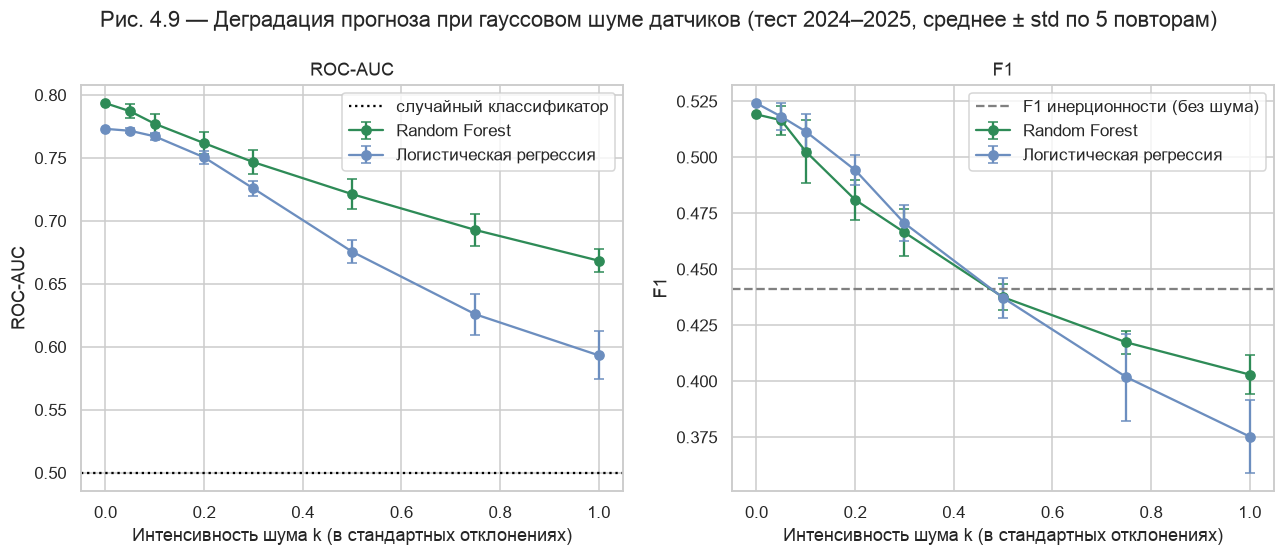

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric in zip(axes, ["ROC-AUC", "F1"]):
    for m, col in zip(MODELS, ["#2E8B57", "#6C8EBF"]):
        g = gauss.loc[m, metric]
        ax.errorbar(g.index, g["mean"], yerr=g["std"], fmt="o-", color=col, capsize=3, label=m)
    ax.set(xlabel="Интенсивность шума k (в стандартных отклонениях)", ylabel=metric, title=metric)
axes[1].axhline(0.441, ls="--", color="gray", label="F1 инерционности (без шума)")
axes[0].axhline(0.5, ls=":", color="black", label="случайный классификатор")
for ax in axes: ax.legend()
fig.suptitle("Рис. 4.9 — Деградация прогноза при гауссовом шуме датчиков (тест 2024–2025, среднее ± std по 5 повторам)", y=1.02)
save("fig_4_9_gaussian_noise")

**Интерпретация.**
- Обе модели деградируют **плавно и предсказуемо** — «порога обрушения» нет.
- При малом шуме (k = 0.05: давление ≈ ±0.4 гПа, температура ≈ ±0.5 °C — точность обычной метеостанции) потеря пренебрежимо мала (ROC-AUC −0.006). При k = 0.1 потеря −0.016.
- При сильном шуме (k ≥ 0.5) F1 опускается **ниже уровня инерционности** (0.44): очень неточный датчик делает модель менее полезной, чем правило «завтра как сегодня».
- **Random Forest устойчивее к сильному шуму** (ROC-AUC 0.67 при k = 1 против 0.59 у логистической регрессии): усреднение сотен деревьев и крупные листья (минимум 20 примеров) сглаживают аномальные значения.

## C.2 Пропуски в данных и способы их заполнения (интерполяция)

Случайно удаляем долю измеренных значений (отдельные ячейки) и заполняем их тремя способами:
- **линейная интерполяция** по времени (между предыдущим и следующим днём) — *внимание*: в реальном времени следующий день неизвестен, поэтому метод оптимистичен;
- **последнее известное значение** (forward fill) — единственный метод, реализуемый в реальном времени;
- **климатическое среднее** (среднее по обучающей выборке).

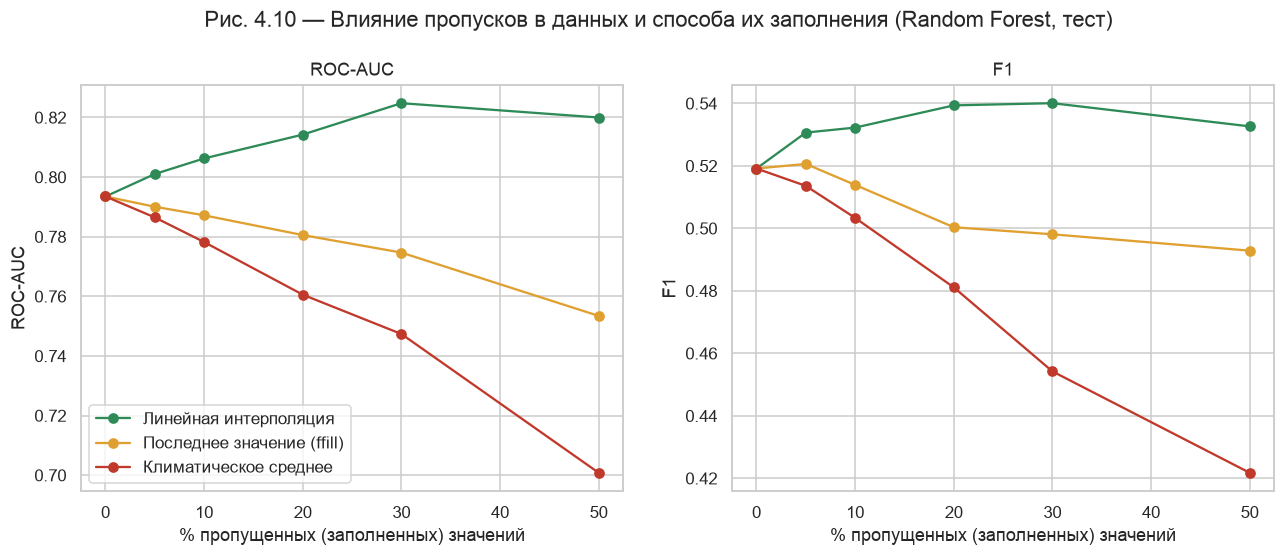

ROC-AUC                        \
Метод          Климатическое среднее Линейная интерполяция   
Доля пропусков                                               
0.00                           0.793                 0.793   
0.05                           0.786                 0.801   
0.10                           0.778                 0.806   
0.20                           0.761                 0.814   
0.30                           0.747                 0.825   
0.50                           0.701                 0.820   

                                                             F1  \
Метод          Последнее значение (ffill) Климатическое среднее   
Доля пропусков                                                    
0.00                                0.793                 0.519   
0.05                                0.790                 0.514   
0.10                                0.787                 0.503   
0.20                                0.781                 0.481   
0.30                                0.775                 0.454   
0.50                                0.753                 0.422   

                                                                 
Метод          Линейная интерполяция Последнее значение (ffill)  
Доля пропусков                                                   
0.00                           0.519                      0.519  
0.05                           0.531                      0.521  
0.10                           0.532                      0.514  
0.20                           0.539                      0.500  
0.30                           0.540                      0.498  
0.50                           0.533                      0.493

In [17]:
INTERP, FFILL, MEAN = "Линейная интерполяция", "Последнее значение (ffill)", "Климатическое среднее"

def add_gaps(raw_in, frac, method, rng):
    r = raw_in.copy()
    idx = np.where(NOISY_PERIOD.values)[0]
    block = r.loc[idx, SENSOR_COLS].copy()
    mask = rng.random(block.shape) < frac
    block = block.mask(mask)
    if method == INTERP:
        block = block.interpolate(limit_direction="both")
    elif method == FFILL:
        block = block.ffill().bfill()
    elif method == MEAN:
        block = block.fillna(raw[raw.date.dt.year <= 2022][SENSOR_COLS].mean())
    r.loc[idx, SENSOR_COLS] = block.values
    return clip_physical(r)

gap_rows = []
for frac in [0, 0.05, 0.1, 0.2, 0.3, 0.5]:
    for method in [INTERP, FFILL, MEAN]:
        for rep in range(5 if frac > 0 else 1):
            auc, f1 = evaluate_raw(add_gaps(raw, frac, method, np.random.default_rng(rep)), {RF: MODELS[RF]})[RF]
            gap_rows.append({"Доля пропусков": frac, "Метод": method, "ROC-AUC": auc, "F1": f1})
gaps = pd.DataFrame(gap_rows).groupby(["Метод", "Доля пропусков"])[["ROC-AUC", "F1"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric in zip(axes, ["ROC-AUC", "F1"]):
    for method, col in zip([INTERP, FFILL, MEAN], ["#2E8B57", "#E0A030", "#C0392B"]):
        g = gaps.loc[method, metric]
        ax.plot(g.index * 100, g.values, "o-", color=col, label=method)
    ax.set(xlabel="% пропущенных (заполненных) значений", ylabel=metric, title=metric)
axes[0].legend()
fig.suptitle("Рис. 4.10 — Влияние пропусков в данных и способа их заполнения (Random Forest, тест)", y=1.02)
save("fig_4_10_gaps")
gaps.unstack(0).round(3)

**Интерпретация.**
- **Последнее известное значение (ffill)** — единственный метод, реализуемый в реальном времени, — устойчив: даже при 50 % пропусков ROC-AUC падает лишь до 0.75 (−0.04).
- **Климатическое среднее** хуже всего (0.70 при 50 % пропусков): оно заменяет реальную погоду «средней погодой» и стирает именно важные сигналы (падение давления, рост влажности).
- **Линейная интерполяция как будто улучшает результаты** (ROC-AUC до 0.82–0.83) — но это **утечка информации из будущего (data leakage)**: пропущенное сегодняшнее значение интерполируется по значению **завтрашнего** дня, то есть ровно того дня, который мы пытаемся предсказать. Результат ненастоящий и недостижим при эксплуатации. Это конкретный пример того, как безобидная на вид предобработка может исказить оценку.

## C.3 Неисправный (зависший) датчик

«Замёрзший» датчик передаёт одно и то же значение весь тестовый период (значение первого дня). Измеряем, сколько теряет модель для каждого типа датчика.

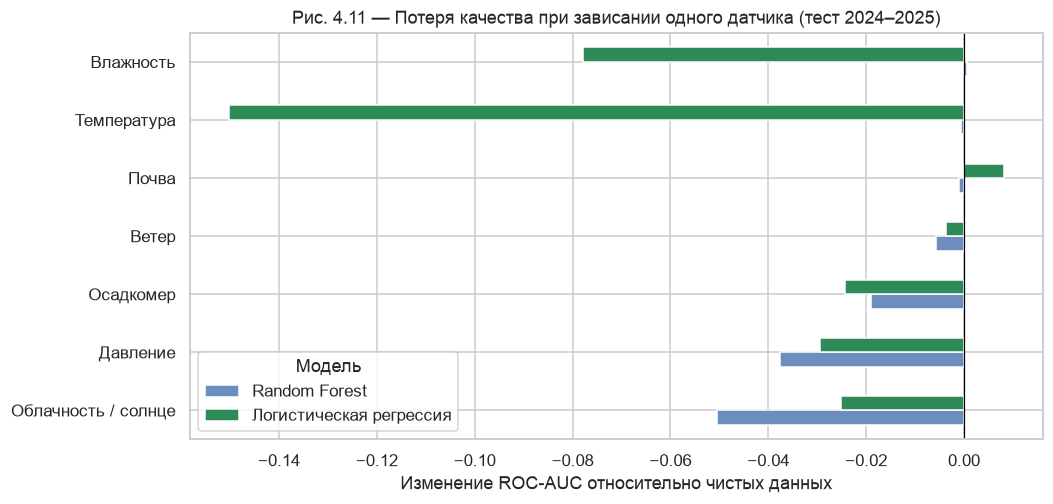

ROC-AUC     F1  Δ ROC-AUC   Δ F1
Зависший датчик     Модель                                                   
Температура         Логистическая регрессия    0.623  0.394     -0.150 -0.130
Влажность           Логистическая регрессия    0.695  0.432     -0.078 -0.092
Облачность / солнце Random Forest              0.743  0.446     -0.050 -0.073
Давление            Random Forest              0.756  0.430     -0.038 -0.089
                    Логистическая регрессия    0.744  0.407     -0.029 -0.117
Облачность / солнце Логистическая регрессия    0.748  0.437     -0.025 -0.087
Осадкомер           Логистическая регрессия    0.749  0.511     -0.024 -0.013
                    Random Forest              0.774  0.528     -0.019  0.008
Ветер               Random Forest              0.788  0.536     -0.006  0.017
                    Логистическая регрессия    0.769  0.521     -0.004 -0.004
Почва               Random Forest              0.793  0.519     -0.001  0.000
Температура         Random Forest              0.793  0.523     -0.001  0.003
Влажность           Random Forest              0.794  0.524      0.001  0.005
Почва               Логистическая регрессия    0.781  0.520      0.008 -0.004

In [18]:
stuck_rows = []
for sensor, cols in SENSORS.items():
    r = raw.copy()
    idx = np.where(NOISY_PERIOD.values)[0]
    r.loc[idx, cols] = r.loc[idx[0], cols].values
    res = evaluate_raw(clip_physical(r), MODELS)
    for m, (auc, f1) in res.items():
        stuck_rows.append({"Зависший датчик": sensor, "Модель": m, "ROC-AUC": auc, "F1": f1,
                           "Δ ROC-AUC": auc - clean[m][0], "Δ F1": f1 - clean[m][1]})
stuck = pd.DataFrame(stuck_rows).set_index(["Зависший датчик", "Модель"]).sort_values("Δ ROC-AUC")

d = stuck["Δ ROC-AUC"].unstack()
d = d.loc[d[RF].sort_values().index]
fig, ax = plt.subplots(figsize=(10, 4.8))
d.plot(kind="barh", ax=ax, color=["#6C8EBF", "#2E8B57"])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Изменение ROC-AUC относительно чистых данных", ylabel="",
       title="Рис. 4.11 — Потеря качества при зависании одного датчика (тест 2024–2025)")
save("fig_4_11_stuck_sensor")
stuck.round(3)

**Интерпретация.**
- **Random Forest устойчив** к зависанию датчиков температуры, влажности, почвы и ветра (потеря ≤ 0.006): избыточные признаки (например, облачность, осадки, давление) компенсируют потерянную информацию.
- **Критичные датчики** для Random Forest — **облачность / солнце** (−0.05 ROC-AUC) и **барометр** (−0.04 ROC-AUC, −0.09 F1) — те же факторы, что оказались важнейшими в ноутбуке 02.
- **Логистическая регрессия хрупкая:** зависший термометр снижает её ROC-AUC на 0.15, потому что производный признак «дефицит точки росы» (T − Td) становится бессмысленным, а линейная модель не может его «проигнорировать».
- **Практическое следствие для RTAP:** система должна следить за **исправностью датчиков** (например, значение, не меняющееся несколько дней подряд = зависший датчик), в первую очередь барометра и датчика облачности.

## C.4 Шум в метках (ошибки регистрации осадков)

До сих пор шум был во **входных данных** (при эксплуатации). Теперь портим **обучающие метки**:
- **симметричный** — у доли дней метка случайно инвертируется (ошибки переписывания);
- **асимметричный** — осадкомер «пропускает» долю дождливых дней (1 → 0), частая ошибка засорённых или обледеневших осадкомеров.

Порог заново выбирается на валидации 2023 (с правильными метками), а тест использует истинные метки.

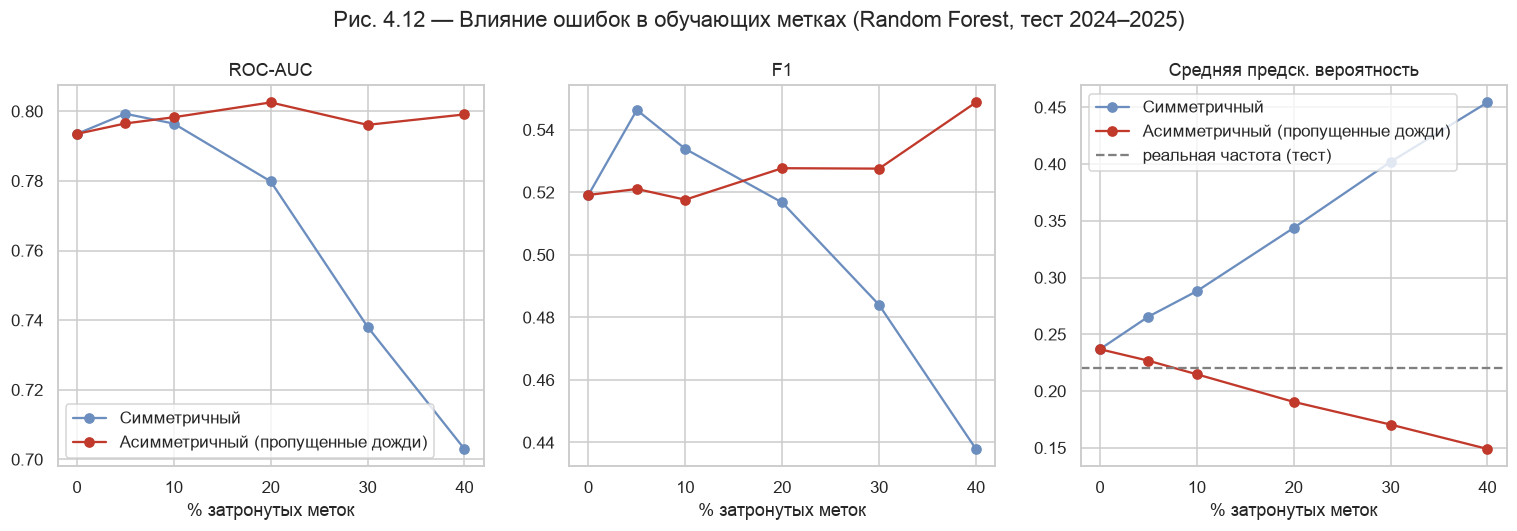

ROC-AUC     F1  \
Тип                               Доля                   
Симметричный                      0.00    0.793  0.519   
                                  0.05    0.799  0.546   
                                  0.10    0.796  0.534   
                                  0.20    0.780  0.517   
                                  0.30    0.738  0.484   
                                  0.40    0.703  0.438   
Асимметричный (пропущенные дожди) 0.00    0.793  0.519   
                                  0.05    0.796  0.521   
                                  0.10    0.798  0.518   
                                  0.20    0.803  0.528   
                                  0.30    0.796  0.528   
                                  0.40    0.799  0.549   

                                        Средняя предск. вероятность  Порог  
Тип                               Доля                                      
Симметричный                      0.00                        0.237   0.23  
                                  0.05                        0.266   0.30  
                                  0.10                        0.288   0.28  
                                  0.20                        0.344   0.37  
                                  0.30                        0.402   0.42  
                                  0.40                        0.454   0.47  
Асимметричный (пропущенные дожди) 0.00                        0.237   0.23  
                                  0.05                        0.227   0.18  
                                  0.10                        0.215   0.18  
                                  0.20                        0.190   0.19  
                                  0.30                        0.170   0.19  
                                  0.40                        0.149   0.16

In [19]:
SYM, ASYM = "Симметричный", "Асимметричный (пропущенные дожди)"
lab_rows = []
for kind in [SYM, ASYM]:
    for frac in [0, 0.05, 0.1, 0.2, 0.3, 0.4]:
        rng = np.random.default_rng(SEED)
        y_noisy = y_tr.to_numpy(copy=True)
        if kind == SYM:
            flip = rng.random(len(y_noisy)) < frac
            y_noisy[flip] = 1 - y_noisy[flip]
        else:
            flip = (y_noisy == 1) & (rng.random(len(y_noisy)) < frac)
            y_noisy[flip] = 0
        m = clone(rf_base).fit(X_tr, y_noisy)
        pv, pt = m.predict_proba(X_va)[:, 1], m.predict_proba(X_te)[:, 1]
        t = tune_threshold(y_va, pv)
        lab_rows.append({"Тип": kind, "Доля": frac, "ROC-AUC": roc_auc_score(y_te, pt), "F1": f1_score(y_te, pt >= t),
                         "Средняя предск. вероятность": pt.mean(), "Порог": t})
labn = pd.DataFrame(lab_rows).set_index(["Тип", "Доля"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ["ROC-AUC", "F1", "Средняя предск. вероятность"]):
    for kind, col in zip([SYM, ASYM], ["#6C8EBF", "#C0392B"]):
        g = labn.loc[kind, metric]
        ax.plot(g.index * 100, g.values, "o-", color=col, label=kind)
    ax.set(xlabel="% затронутых меток", title=metric)
axes[2].axhline(y_te.mean(), ls="--", color="gray", label="реальная частота (тест)")
axes[0].legend(); axes[2].legend()
fig.suptitle("Рис. 4.12 — Влияние ошибок в обучающих метках (Random Forest, тест 2024–2025)", y=1.03)
save("fig_4_12_label_noise")
labn.round(3)

**Интерпретация.**
- **Симметричный шум** до 10–20 % почти не влияет на модель (ROC-AUC ≈ 0.78–0.80); при 30–40 % ROC-AUC падает до 0.70–0.74. Random Forest «сглаживает» отдельные ошибки голосованием.
- **Пропущенные дожди** (асимметричный шум) **не влияют на ROC-AUC** (≈ 0.80 даже при 40 %): порядок дней по риску остаётся правильным. Но **вероятности систематически занижаются** (0.149 при 40 % против реальной частоты 0.221).
- F1 остаётся хорошим только потому, что порог выбран на **правильных** метках (2023). Если бы и валидация была испорчена, модель систематически пропускала бы дожди — см. смещение измерений в разделе D.3.

---
# D. Bias — географическая справедливость и преобладающие паттерны

## D.1 Географическая справедливость: модель Кишинёва в других населённых пунктах

Модель обучена только на данных **столицы**. Национальная служба прогнозов должна одинаково хорошо работать по всей стране.
Применяем модель Кишинёва (без переобучения, с тем же порогом) к 2024–2025 в 5 населённых пунктах из всех регионов и сравниваем её с **локальной моделью** (те же параметры, обучена на данных этого пункта за 2015–2022, порог выбран на 2023).

> **Ограничение:** у ERA5 разрешение ~25–30 км, и он не моделирует городской эффект (городской остров тепла). Поэтому можно проверить **региональную** справедливость, но не разницу «город – село»; для этого нужны данные городских и сельских метеостанций.

In [20]:
CITIES = {"Кишинёв": ("chisinau", 47.01, 28.86), "Сороки": ("soroca", 48.16, 28.30), "Бельцы": ("balti", 47.76, 27.93),
          "Унгены": ("ungheni", 47.21, 27.80), "Комрат": ("comrat", 46.30, 28.66), "Кагул": ("cahul", 45.90, 28.19)}
geo_rows = []
for city, (slug, lat, lon) in CITIES.items():
    f = load_dataset(slug)               # the same SQL query, another station
    ctr, cva, cte = f[f.date.dt.year <= 2022], f[f.date.dt.year == 2023], f[f.date.dt.year >= 2024]
    p_ch = rf_base.predict_proba(cte[FEATURES])[:, 1]
    local = clone(rf_base).fit(ctr[FEATURES], ctr[TARGET])
    t_loc = tune_threshold(cva[TARGET], local.predict_proba(cva[FEATURES])[:, 1])
    p_loc = local.predict_proba(cte[FEATURES])[:, 1]
    geo_rows.append({"Населённый пункт": city, "lat": lat, "lon": lon, "% дней с осадками": cte[TARGET].mean() * 100,
                     "ROC-AUC (модель Кишинёва)": roc_auc_score(cte[TARGET], p_ch),
                     "F1 (модель Кишинёва)": f1_score(cte[TARGET], p_ch >= THR),
                     "Recall (модель Кишинёва)": recall_score(cte[TARGET], p_ch >= THR),
                     "ROC-AUC (локальная модель)": roc_auc_score(cte[TARGET], p_loc),
                     "F1 (локальная модель)": f1_score(cte[TARGET], p_loc >= t_loc),
                     "Средняя предск. вероятность, %": p_ch.mean() * 100})
geo = pd.DataFrame(geo_rows).set_index("Населённый пункт")
geo["Δ F1 (Кишинёв − локальная)"] = geo["F1 (модель Кишинёва)"] - geo["F1 (локальная модель)"]
geo.drop(columns=["lat", "lon"]).round(3)

,% дней с осадками,ROC-AUC (модель Кишинёва),F1 (модель Кишинёва),Recall (модель Кишинёва),ROC-AUC (локальная модель),F1 (локальная модель),"Средняя предск. вероятность, %",Δ F1 (Кишинёв − локальная)
Населённый пункт,,,,,,,,
Кишинёв,22.055,0.793,0.519,0.758,0.793,0.519,23.687,0.000
Сороки,26.438,0.767,0.564,0.798,0.769,0.558,25.465,0.006
Бельцы,24.795,0.762,0.531,0.757,0.774,0.519,24.958,0.012
Унгены,23.699,0.762,0.510,0.734,0.761,0.517,24.458,-0.007
Комрат,19.589,0.771,0.468,0.713,0.778,0.500,22.442,-0.032
Кагул,19.315,0.790,0.501,0.759,0.788,0.514,22.237,-0.013


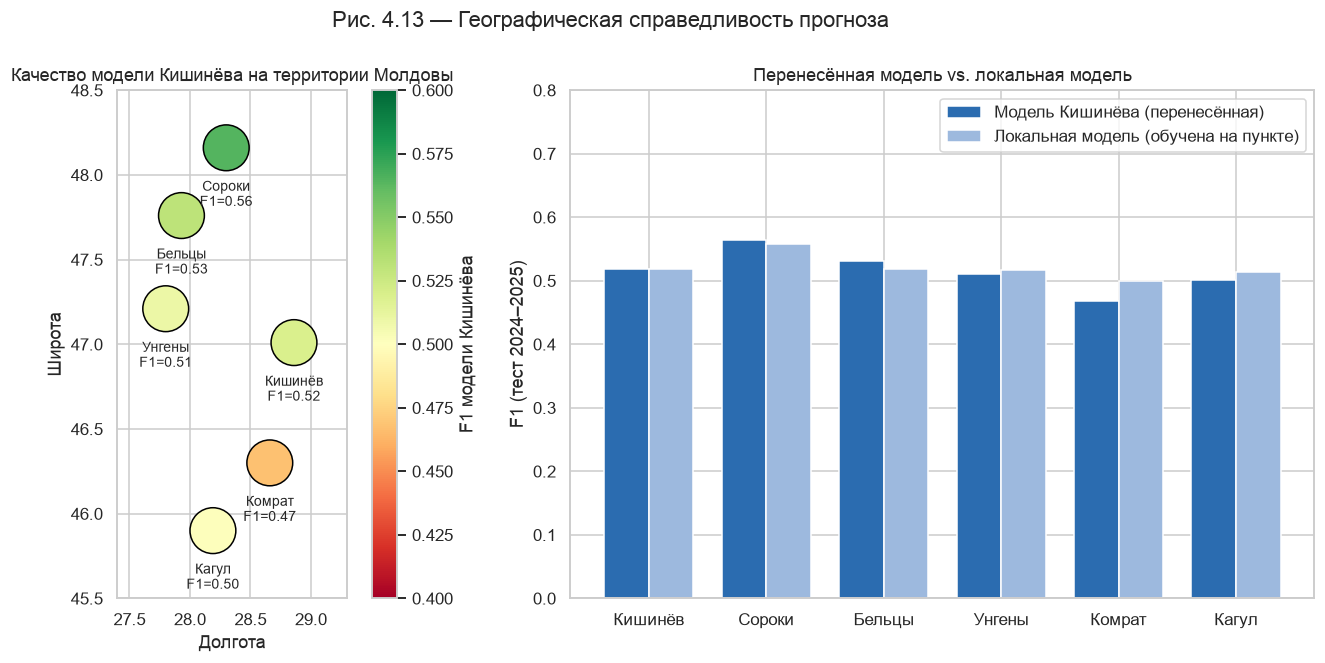

In [21]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.5]})
sc = a1.scatter(geo.lon, geo.lat, s=900, c=geo["F1 (модель Кишинёва)"], cmap="RdYlGn", vmin=0.4, vmax=0.6, edgecolor="black")
for city, r in geo.iterrows():
    a1.annotate(f"{city}\nF1={r['F1 (модель Кишинёва)']:.2f}", (r.lon, r.lat), xytext=(0, -38), textcoords="offset points",
                ha="center", fontsize=9)
plt.colorbar(sc, ax=a1, label="F1 модели Кишинёва")
a1.set(xlim=(27.4, 29.3), ylim=(45.5, 48.5), xlabel="Долгота", ylabel="Широта",
       title="Качество модели Кишинёва на территории Молдовы"); a1.set_aspect(1.4)
x = np.arange(len(geo)); w = 0.38
a2.bar(x - w / 2, geo["F1 (модель Кишинёва)"], w, color="#2B6CB0", label="Модель Кишинёва (перенесённая)")
a2.bar(x + w / 2, geo["F1 (локальная модель)"], w, color="#9DB9DE", label="Локальная модель (обучена на пункте)")
a2.set_xticks(x, geo.index); a2.set_ylim(0, 0.8); a2.set_ylabel("F1 (тест 2024–2025)"); a2.legend()
a2.set_title("Перенесённая модель vs. локальная модель")
fig.suptitle("Рис. 4.13 — Географическая справедливость прогноза", y=1.0)
save("fig_4_13_geographic_fairness")

**Интерпретация.**
- Модель, обученная только на Кишинёве, **хорошо переносится** на всю страну: ROC-AUC 0.76–0.79 и F1 0.47–0.56 во всех пунктах.
- Локальные модели **лишь незначительно лучше** (ΔF1 от −0.03 до +0.01). Молдова — маленькая страна (~350 км с севера на юг) с одинаковыми атмосферными процессами, поэтому модель столицы не «обделяет» регионы.
- Наименьший F1 в **Комрате** (0.47), но и локальная модель получает лишь 0.50: юг засушливее (≈ 19–20 % дней с осадками против 26 % в Сороках), а более редкий положительный класс естественно снижает F1.
- Есть **небольшое географическое смещение калибровки**: на юге (Комрат, Кагул) модель завышает вероятность осадков (≈ 22 % предсказано против ≈ 19–20 % реально → больше ложных тревог), а на севере (Сороки) слегка занижает (25.5 % против 26.4 %). Простое решение — перекалибровать порог для каждого региона.

## D.2 Преобладающие vs. редкие погодные паттерны

Модель учится в основном на **частых** ситуациях. Проверим, насколько хорошо она находит осадки в зависимости от:
- их **интенсивности** (слабые дожди vs. сильные — самые важные для предупреждений);
- **направления ветра** сегодня (преобладающий сектор СЗ vs. редкие сектора);
- **типа критической погоды** (какие опасные явления модель «видит»).

In [22]:
nxt = raw.set_index("date").precipitation_sum.shift(-1)
t = test.assign(p=rf_base.predict_proba(X_te)[:, 1], precip_next=test.date.map(nxt))
t["pred"] = (t.p >= THR).astype(int)

rain = t[t[TARGET] == 1]
rain_bins = pd.cut(rain.precip_next, [1, 3, 10, 100], right=False, labels=["Слабые (1–3 мм)", "Умеренные (3–10 мм)", "Сильные (≥ 10 мм)"])
by_int = rain.groupby(rain_bins, observed=True).agg(**{"Дней": ("pred", "size"), "Recall": ("pred", "mean"),
                                                      "Средняя вероятность": ("p", "mean")})

SECTORS = ["С–СВ", "СВ–В", "В–ЮВ", "ЮВ–Ю", "Ю–ЮЗ", "ЮЗ–З", "З–СЗ", "СЗ–С"]
sector = pd.cut(raw.set_index("date").wind_direction_10m_dominant.reindex(t.date).values % 360,
                bins=[0, 45, 90, 135, 180, 225, 270, 315, 360], right=False, labels=SECTORS)
by_dir = []
for s in sector.categories:
    m = (sector == s)
    tt = t[m]
    by_dir.append({"Сектор": s, "% дней": m.mean() * 100, "Дождливых дней": int(tt[TARGET].sum()),
                   "Recall": recall_score(tt[TARGET], tt.pred) if tt[TARGET].sum() else np.nan,
                   "Precision": precision_score(tt[TARGET], tt.pred, zero_division=0),
                   "ROC-AUC": roc_auc_score(tt[TARGET], tt.p) if tt[TARGET].nunique() == 2 else np.nan})
by_dir = pd.DataFrame(by_dir).set_index("Сектор")

next_raw = raw.set_index("date").shift(-1).reindex(t.date)
crit_kinds = {"Сильный дождь ≥ 10 мм": next_raw.precipitation_sum.values >= CRITICAL["precip_mm"],
              "Сильный ветер ≥ 60 км/ч": next_raw.wind_gusts_10m_max.values >= CRITICAL["gusts_kmh"],
              "Жара ≥ 35 °C": next_raw.temperature_2m_max.values >= CRITICAL["tmax_c"],
              "Мороз ≤ −15 °C": next_raw.temperature_2m_min.values <= CRITICAL["tmin_c"],
              "Снегопад ≥ 5 см": next_raw.snowfall_sum.values >= CRITICAL["snow_cm"]}
# use the 3-class classifier balanced with class_weight (the best strategy from section B)
rf3_bal = strategy_pipe("class_weight", rf_base).fit(X_tr, z_tr)
p3 = rf3_bal.predict(X_te)
by_crit = pd.DataFrame([{"Явление (завтра)": k, "Дней в тесте": int(m.sum()),
                         "Предсказано как «критическая»": int((p3[m] == 2).sum()) if m.sum() else 0,
                         "Предсказано как «неблагопр.» или «критическая»": int((p3[m] >= 1).sum()) if m.sum() else 0}
                        for k, m in crit_kinds.items()]).set_index("Явление (завтра)")
display(by_int.round(3)); display(by_dir.round(3)); display(by_crit)

,Дней,Recall,Средняя вероятность
precip_next,,,
Слабые (1–3 мм),75,0.693,0.349
Умеренные (3–10 мм),55,0.727,0.360
Сильные (≥ 10 мм),31,0.968,0.505


,% дней,Дождливых дней,Recall,Precision,ROC-AUC
Сектор,,,,,
С–СВ,9.589,17,0.647,0.579,0.818
СВ–В,9.178,20,0.850,0.472,0.845
В–ЮВ,8.356,25,0.800,0.588,0.807
ЮВ–Ю,16.438,29,0.897,0.419,0.847
Ю–ЮЗ,7.671,12,0.833,0.357,0.756
ЮЗ–З,6.849,9,0.667,0.250,0.661
З–СЗ,18.493,25,0.640,0.291,0.725
СЗ–С,23.425,24,0.667,0.314,0.768


,Дней в тесте,Предсказано как «критическая»,Предсказано как «неблагопр.» или «критическая»
Явление (завтра),,,
Сильный дождь ≥ 10 мм,31,20,29
Сильный ветер ≥ 60 км/ч,16,6,15
Жара ≥ 35 °C,10,2,10
Мороз ≤ −15 °C,1,1,1
Снегопад ≥ 5 см,1,1,1


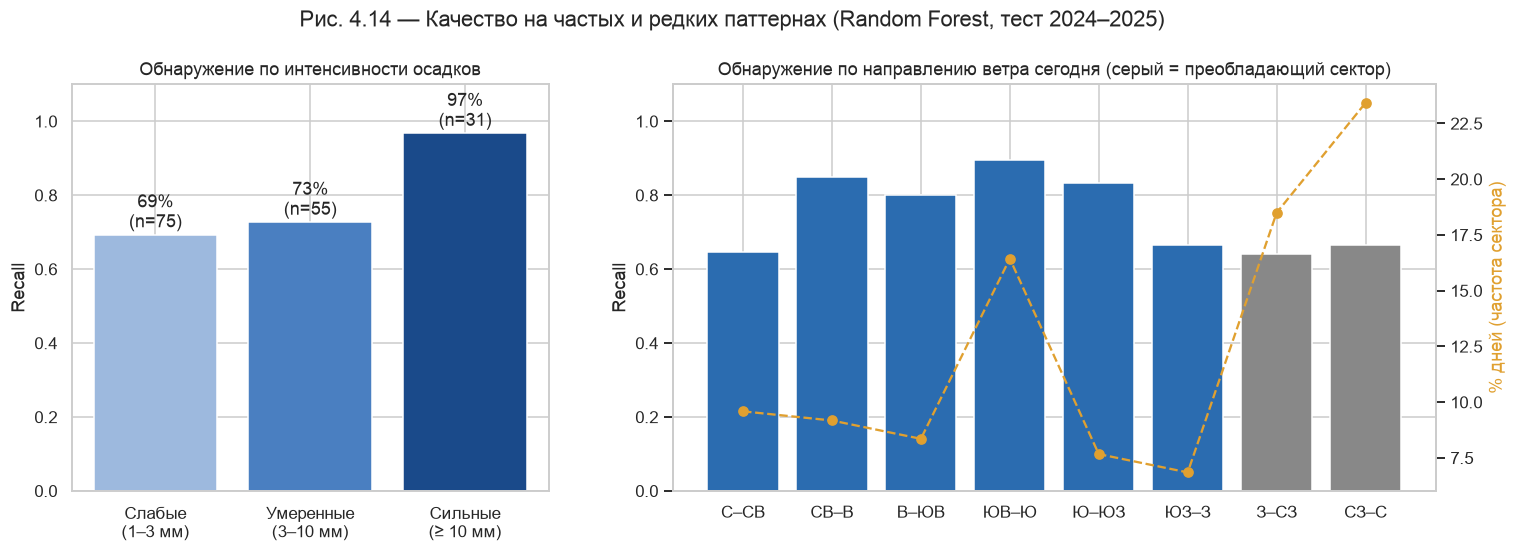

In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
a1.bar(by_int.index.astype(str).str.replace(" (", "\n("), by_int.Recall, color=["#9DB9DE", "#4A7FC1", "#1A4A8A"])
for i, (r, n) in enumerate(zip(by_int.Recall, by_int["Дней"])):
    a1.text(i, r + 0.02, f"{r:.0%}\n(n={n})", ha="center")
a1.set(ylim=(0, 1.1), ylabel="Recall", title="Обнаружение по интенсивности осадков")
x = np.arange(len(by_dir))
a2.bar(x, by_dir.Recall, color=np.where(by_dir.index.isin(["З–СЗ", "СЗ–С"]), "#888888", "#2B6CB0"))
a2b = a2.twinx(); a2b.plot(x, by_dir["% дней"], "o--", color="#E0A030"); a2b.set_ylabel("% дней (частота сектора)", color="#E0A030")
a2b.grid(False)
a2.set_xticks(x, by_dir.index); a2.set(ylim=(0, 1.1), ylabel="Recall", title="Обнаружение по направлению ветра сегодня (серый = преобладающий сектор)")
fig.suptitle("Рис. 4.14 — Качество на частых и редких паттернах (Random Forest, тест 2024–2025)", y=1.02)
save("fig_4_14_patterns")

**Интерпретация.**
- **Сильные осадки** (≥ 10 мм) обнаруживаются в **97 %** случаев (30 из 31), слабые — в 69 %. Модель лучше всего ловит именно самые важные для предупреждений события.
- По направлению ветра результат **обратен ожиданиям**: модель не «благоприятствует» преобладающему паттерну, а, наоборот, хуже всего работает в преобладающем **северо-западном** секторе (42 % дней; Recall ≈ 0.64–0.67, Precision ≈ 0.3). Дождь при северо-западном (обычно сухом) потоке нетипичен и трудно предсказуем, а «классические» для Молдовы дожди сектора В–Ю обнаруживаются в 80–90 % случаев. У сектора ЮЗ–З самый низкий ROC-AUC (0.66), но всего 9 дождливых дней — слишком малая выборка для твёрдого вывода.
- **Критические явления** (3-классовая сбалансированная модель): сильный дождь помечен «критическим» в 20 из 31 случая (29 из 31 — хотя бы «неблагоприятным»), сильный ветер — 6 из 16 (15 из 16), а **жара лишь 2 из 10** (но 10 из 10 — «неблагоприятная»). Модель **недооценивает опасность жары**: очень жаркие дни выглядят как обычные тёплые, поэтому классифицируются как «неблагоприятные». Для жары лучше подошёл бы отдельный прогноз температуры (регрессия).

## D.3 Контролируемо внесённое смещение

Намеренно вносим два типичных искажения в обучающие данные и измеряем эффект (карточка темы рекомендует проверять устойчивость к контролируемому смещению).

**(a) Смещение выборки по сезону** — обучающие данные только из тёплого сезона (апрель–сентябрь), например со станции, работающей только летом.
Сравниваем с моделью, обученной на **таком же числе** дней, выбранных случайно из всего года, — чтобы разница не объяснялась объёмом данных.

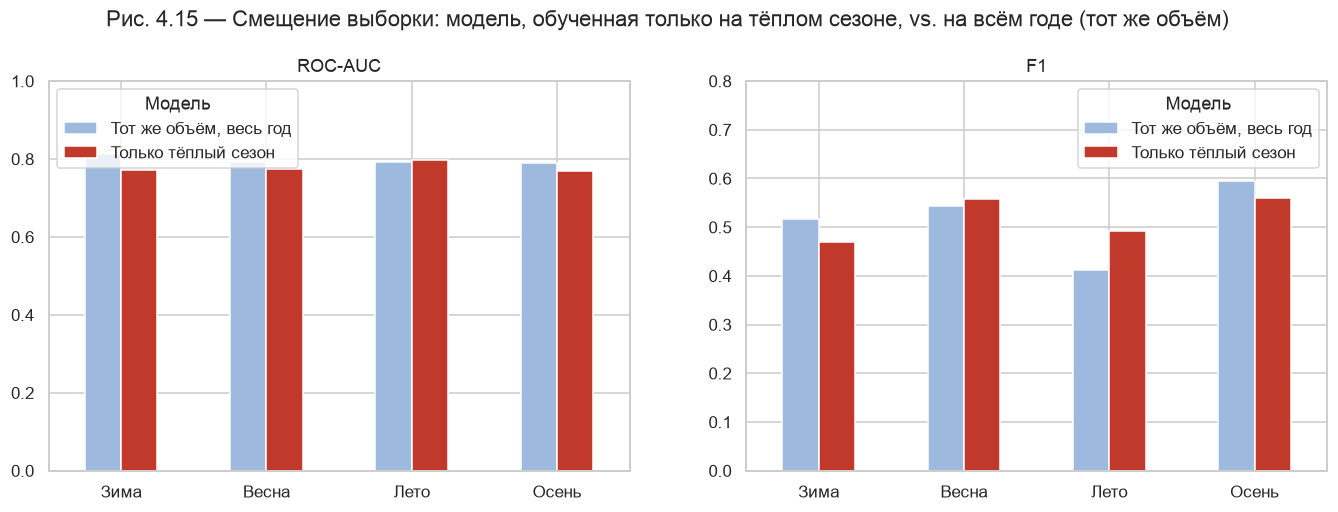

ROC-AUC     F1  Средняя предск. вероятность  \
Модель                 Сезон                                                
Только тёплый сезон    Зима     0.772  0.470                        0.326   
                       Весна    0.773  0.557                        0.293   
                       Лето     0.796  0.492                        0.211   
                       Осень    0.768  0.561                        0.296   
Тот же объём, весь год Зима     0.813  0.517                        0.242   
                       Весна    0.791  0.543                        0.262   
                       Лето     0.791  0.412                        0.209   
                       Осень    0.791  0.595                        0.251   

                              Реальная частота  
Модель                 Сезон                    
Только тёплый сезон    Зима              0.211  
                       Весна             0.255  
                       Лето              0.152  
                       Осень             0.264  
Тот же объём, весь год Зима              0.211  
                       Весна             0.255  
                       Лето              0.152  
                       Осень             0.264

In [24]:
warm = train.date.dt.month.between(4, 9)
X_w, y_w = X_tr[warm], y_tr[warm]
rand_idx = train.sample(n=warm.sum(), random_state=SEED).index
WARM, ALLY = "Только тёплый сезон", "Тот же объём, весь год"
models_bias = {WARM: clone(rf_base).fit(X_w, y_w),
               ALLY: clone(rf_base).fit(X_tr.loc[rand_idx], y_tr.loc[rand_idx])}
season_te = test.date.dt.month.map(SEASONS).values
sb_rows = []
for name, m in models_bias.items():
    t_ = tune_threshold(y_va, m.predict_proba(X_va)[:, 1])
    p = m.predict_proba(X_te)[:, 1]
    for s in ["Зима", "Весна", "Лето", "Осень"]:
        k = season_te == s
        sb_rows.append({"Модель": name, "Сезон": s, "ROC-AUC": roc_auc_score(y_te[k], p[k]), "F1": f1_score(y_te[k], p[k] >= t_),
                        "Средняя предск. вероятность": p[k].mean(), "Реальная частота": y_te[k].mean()})
sbias = pd.DataFrame(sb_rows).set_index(["Модель", "Сезон"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, metric in zip(axes, ["ROC-AUC", "F1"]):
    sbias[metric].unstack(0).loc[["Зима", "Весна", "Лето", "Осень"], [ALLY, WARM]].plot(kind="bar", ax=ax, color=["#9DB9DE", "#C0392B"], rot=0)
    ax.set(title=metric, xlabel=""); ax.set_ylim(0, 1 if metric == "ROC-AUC" else 0.8)
fig.suptitle("Рис. 4.15 — Смещение выборки: модель, обученная только на тёплом сезоне, vs. на всём годе (тот же объём)", y=1.02)
save("fig_4_15_seasonal_bias")
sbias.round(3)

**(b) Смещение измерений (недоучёт осадкомера).** Реальные осадкомеры систематически занижают осадки (ветер, испарение, снег): на 5–20 %, а при снегопаде ещё сильнее.
Моделируем осадкомер, регистрирующий лишь долю $f$ реальных осадков. Модель обучается и порог выбирается по **искажённым меткам** (оператор не знает об ошибке), а оценка проводится по **истинным** меткам.

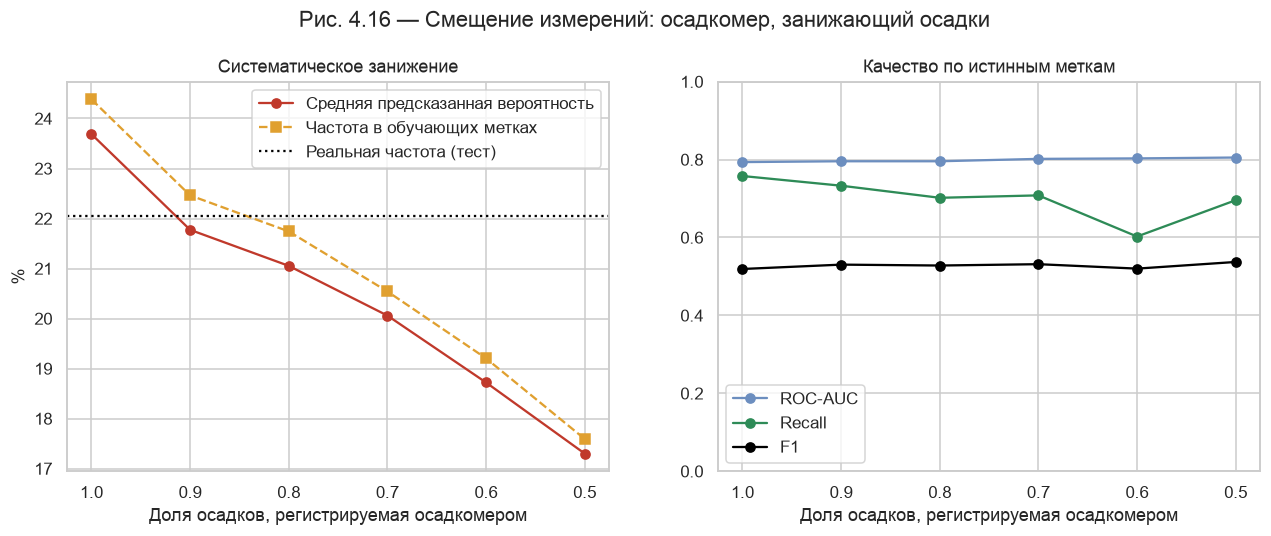

,% «дождливых» дней в обучении,"Средняя предск. вероятность, %","Реальная частота (тест), %",ROC-AUC,Recall,F1
Регистрируемая доля f,,,,,,
1.0,24.383,23.687,22.055,0.793,0.758,0.519
0.9,22.462,21.774,22.055,0.796,0.733,0.530
0.8,21.742,21.053,22.055,0.796,0.702,0.528
0.7,20.542,20.059,22.055,0.802,0.708,0.531
0.6,19.204,18.721,22.055,0.803,0.602,0.520
0.5,17.593,17.301,22.055,0.805,0.696,0.537


In [25]:
precip_next = raw.set_index("date").precipitation_sum.shift(-1)
mb_rows = []
for f in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    yb_tr = (train.date.map(precip_next) * f >= RAIN_MM).astype(int)
    yb_va = (valid.date.map(precip_next) * f >= RAIN_MM).astype(int)
    m = clone(rf_base).fit(X_tr, yb_tr)
    t_ = tune_threshold(yb_va, m.predict_proba(X_va)[:, 1])
    p = m.predict_proba(X_te)[:, 1]
    mb_rows.append({"Регистрируемая доля f": f, "% «дождливых» дней в обучении": yb_tr.mean() * 100,
                    "Средняя предск. вероятность, %": p.mean() * 100, "Реальная частота (тест), %": y_te.mean() * 100,
                    "ROC-AUC": roc_auc_score(y_te, p), "Recall": recall_score(y_te, p >= t_), "F1": f1_score(y_te, p >= t_)})
mbias = pd.DataFrame(mb_rows).set_index("Регистрируемая доля f")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6))
a1.plot(mbias.index, mbias["Средняя предск. вероятность, %"], "o-", color="#C0392B", label="Средняя предсказанная вероятность")
a1.plot(mbias.index, mbias["% «дождливых» дней в обучении"], "s--", color="#E0A030", label="Частота в обучающих метках")
a1.axhline(y_te.mean() * 100, ls=":", color="black", label="Реальная частота (тест)")
a1.invert_xaxis(); a1.set(xlabel="Доля осадков, регистрируемая осадкомером", ylabel="%", title="Систематическое занижение")
a1.legend()
for metric, col in zip(["ROC-AUC", "Recall", "F1"], ["#6C8EBF", "#2E8B57", "black"]):
    a2.plot(mbias.index, mbias[metric], "o-", color=col, label=metric)
a2.invert_xaxis(); a2.set(xlabel="Доля осадков, регистрируемая осадкомером", ylim=(0, 1), title="Качество по истинным меткам")
a2.legend()
fig.suptitle("Рис. 4.16 — Смещение измерений: осадкомер, занижающий осадки", y=1.02)
save("fig_4_16_measurement_bias")
mbias.round(3)

**Интерпретация.**

**(a) Сезонное смещение выборки.** Модель, обученная только на тёплом сезоне, больше всего теряет **зимой** (ROC-AUC 0.77 против 0.81, F1 0.47 против 0.52) и систематически **завышает** шанс осадков в холодный сезон (предсказывает 33 % зимой при реальных 21 %). Зато летом она даже немного лучше (F1 0.49 против 0.41) — она «специализировалась». **Урок:** ошибки перемещаются туда, где не хватает обучающих данных — «кто остаётся невидимым для алгоритма» — это ситуации, которых модель не видела.

**(b) Смещение измерений.** Осадкомер, регистрирующий лишь 50–90 % осадков, заставляет модель **систематически занижать** вероятность дождя (17 % предсказано при f = 0.5 против 22 % реально). **ROC-AUC не замечает проблемы** (остаётся ≈ 0.80, так как порядок дней по риску не меняется), но **Recall падает** (0.76 → 0.60–0.71) — пропускается больше дождей. Смещение измерений **невидимо в метриках ранжирования** и проявляется только в **калибровке** (средняя вероятность vs. реальная частота). Поэтому приборы нужно поверять и сравнивать с независимым источником.

---
# Выводы ноутбука (элементы Decision Boundaries, SMOTE, Noise, Bias)

| Элемент | Главный результат |
|---|---|
| **Decision Boundaries** | Погода завтра делится на 3 типа (55.7 % / 37.5 % / 6.7 %). Классы сильно перекрываются; критическая погода образует две отдельные группы (грозы при низком давлении, жара при сухом тёплом воздухе) и не имеет единой «подписи». Границы линейные (LR), гладкие (SVM) или ступенчатые (RF). |
| **SMOTE** | Без балансировки критический класс не предсказывается никогда. SMOTE поднимает Recall критического класса с 0 до 0.30–0.42 (RF) и до 0.49 (LR); для RF `class_weight` оказался ещё лучше (0.51). В бинарной задаче SMOTE ≈ сдвиг порога и портит калибровку. |
| **Noise** | Плавная деградация: реалистичный шум датчиков (k ≤ 0.05) пренебрежим; RF устойчивее LR. Пропуски лучше всего заполнять последним значением; линейная интерполяция даёт утечку информации из будущего. Критичные датчики: барометр и облачность. |
| **Bias** | Географическая справедливость хорошая (ΔF1 ≤ 0.03 относительно локальных моделей), с лёгким завышением на юге. Сильные осадки обнаруживаются в 97 % случаев, но опасность жары недооценивается. Смещение выборки переносит ошибки в «невидимый» сезон; смещение измерений (осадкомер) невидимо в ROC-AUC и проявляется только в калибровке. |

**Связь с исследовательским вопросом — «Что говорит небо, прежде чем заговорить?»:** небо «говорит» через **давление** (его падение предвещает непогоду), **облачность** и **направление ветра**. Алгоритм хорошо слышит сильные сигналы (сильные осадки, фронты), но плохо слышит локальные и внезапные явления (летние ливни, жару).

**Следующий шаг:** ноутбук `04_Streaming_RTAP.ipynb` — обработка данных день за днём, адаптация модели и модуль автоматических уведомлений.